<a href="https://colab.research.google.com/github/PacktPublishing/Hands-On-Open-Source-Foundation-Models-for-Time-Series-Forecasting/blob/main/Chapter03_Zero_Shot_Forecasting/05b_zero_shot_timestral_ibm_t0_tabpfn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 05b · Zero-shot forecasting with Timestral, IBM's models, t0 and TabPFN-TS

*Hands-On Open-Source Foundation Models for Time Series Forecasting*, Chapter 3: Zero-Shot Forecasting in Practice

This notebook runs Mistral AI's Timestral (209M and 5M), IBM's TTM, FlowState and PatchTST-FM, The Forecasting Company's t0-gamma and Prior Labs' TabPFN-TS zero-shot: the models forecast our series straight away, without any training on
our data. Each model forecasts every dataset, every horizon (7, 14, 30, 60 and 90 days (D1, D2) and 3, 6, 9, 12 and 24 months (D3, D4)) and every rolling window fixed in
Notebook 04.

For each model you will find a figure of its architecture, a plain description of how it works and what is new
about it, what it costs to run, and which covariates it can read without fine-tuning. The figures were checked
against each model's paper, its released configuration and the network as loaded.

#### Why these models share a notebook

They install into the same Python environment (`requirements/env-core.txt`). Foundation-model libraries pin
different versions of `torch`, `numpy` and `transformers`, and these often clash, so the chapter groups the models
by the environment they need rather than by the company that made them.

The datasets are D1 (daily Central England temperature), D2 (D1 with 12 covariates), D3 (five monthly metal prices) and D4 (D3 with three global drivers, each known up to the forecast origin). The bonus datasets B1 and B2 have their own notebook: [bonus/B05b_zero_shot_timestral_ibm_t0_tabpfn.ipynb](bonus/B05b_zero_shot_timestral_ibm_t0_tabpfn.ipynb).

**What you will learn**

- what is inside each model, drawn layer by layer in one consistent style, with the maths of each layer explained
- which models can use past-only and known-future covariates without fine-tuning, and how they do it
- how the models' point forecasts compare across datasets and horizons, by MASE and by RMSE, and what they cost
  to run on a CPU
- how the forecasts look against the actual values at every horizon

| Environment and compute | |
|---|---|
| Python | 3.12 (tested); see *How to run* for Colab |
| Packages | [`requirements/env-core.txt`](requirements/env-core.txt) (pinned) |
| Hardware | CPU only; a GPU is used automatically if present |
| Network | downloads the checkpoints from Hugging Face on first use |
| Run time, quick check (default) | about 2 min of forecasting on 4 CPU cores (Colab's free tier has 2 cores: allow about twice as long) |
| Run time, `FULL_RUN = True` | about 72 min of forecasting with one CPU thread, while other notebooks shared the machine |
| Peak memory | 1.5 GB above the kernel's baseline (largest single call) |

**How to run this notebook**

- **Google Colab:** choose *Runtime > Run all*. The first code cell fetches this chapter's folder and installs `requirements/env-core.txt`
  with uv (a few minutes the first time). If it says it is restarting the session, wait, then choose *Runtime > Run all*
  again. To use your own copy on Google Drive, set `DRIVE_COPY` in that cell to the folder's path. A GPU runtime
  is not needed; if you pick one, the models use it.
- **Your own computer (Cursor, VS Code or Jupyter):** create the environment once with
  `uv venv .venv-core -p 3.12 && uv pip install -p .venv-core -r requirements/env-core.txt`
  (or `python3.12 -m venv .venv-core` and `pip install -r ...`), open this folder, choose the `.venv-core` kernel
  and run all cells.

In [1]:
# Setup: find this chapter's folder (on Colab: fetch it and install this notebook's environment)
import os
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules


def is_chapter(d):
    return (Path(d) / "src" / "ch03_dataprep" / "__init__.py").is_file()


if IN_COLAB:  # get this chapter's folder and install this notebook's environment
    import shutil

    CHAPTER = "Chapter03_Zero_Shot_Forecasting"   # this chapter's folder in the book's repository
    DRIVE_COPY = ""   # optional: path of your own copy of this folder on Google Drive (skips GitHub)
    BOOK = Path("/content/book")

    def chapter_dir():  # this chapter's folder under /content/book, or None until it is there
        return next((d for d in (BOOK / CHAPTER, BOOK) if is_chapter(d)), None)

    def find_in_drive(top="/content/drive/MyDrive", depth=6):  # the copies of CHAPTER, shallowest first
        level = [top]
        for _ in range(depth):
            subdirs = []
            for d in level:
                try:
                    subdirs += [e.path for e in os.scandir(d) if e.is_dir() and not e.name.startswith(".")]
                except OSError:
                    pass
            hits = [d for d in subdirs if Path(d).name == CHAPTER and is_chapter(d)]
            if hits:
                return hits
            level = subdirs
        return []

    def local_only(d, names):  # what not to copy from Drive: local environments, caches, downloaded data
        return [n for n in names if n.startswith(".venv") or n == "__pycache__" or (d.endswith("/data") and n == "raw")]

    if chapter_dir() is None and not DRIVE_COPY:    # 1) clone the book's repository from GitHub
        shutil.rmtree(BOOK, ignore_errors=True)
        !GIT_TERMINAL_PROMPT=0 git clone -q --depth 1 https://github.com/PacktPublishing/Hands-On-Open-Source-Foundation-Models-for-Time-Series-Forecasting /content/book
    if chapter_dir() is None:                       # 2) not on GitHub (yet): copy it from your Google Drive
        from google.colab import drive
        drive.mount("/content/drive")
        if not DRIVE_COPY:
            print(f"{CHAPTER} is not on GitHub: searching My Drive for it (set DRIVE_COPY above to skip this)")
            hits = find_in_drive()
            if len(hits) > 1:
                raise FileExistsError(f"several copies of {CHAPTER} in My Drive: {hits}. Set DRIVE_COPY to one.")
            DRIVE_COPY = hits[0] if hits else ""
        if DRIVE_COPY and not is_chapter(DRIVE_COPY):
            raise FileNotFoundError(f"DRIVE_COPY = {DRIVE_COPY!r} is not this chapter's folder (no src/ch03_dataprep)")
        if DRIVE_COPY:
            print(f"copying {DRIVE_COPY} to {BOOK / CHAPTER} ...")
            shutil.rmtree(BOOK, ignore_errors=True)
            shutil.copytree(DRIVE_COPY, BOOK / "partial-copy", ignore=local_only)
            (BOOK / "partial-copy").rename(BOOK / CHAPTER)    # only a finished copy gets the chapter's name
            print(f"copied {sum(len(files) for _, _, files in os.walk(BOOK / CHAPTER)):,} files")
    if chapter_dir() is None:
        raise FileNotFoundError(f"{CHAPTER} is not in the book's GitHub repository or in your Google Drive. "
                                "Upload the folder to Drive, or set DRIVE_COPY above to its path there.")
    os.chdir(chapter_dir())
    import importlib.metadata as md

    def key(name):  # package installers treat huggingface_hub and huggingface-hub as one package
        return name.lower().replace("_", "-").replace(".", "-")

    def versions():  # the version of every installed package, as Python finds it (first copy on sys.path)
        found = {}
        for d in md.distributions():
            found.setdefault(key(d.metadata["Name"]), d.version)
        return found

    before = versions()
    # Install with uv: it downloads and installs packages in parallel, several times faster than pip. Colab comes
    # with uv (installed here if not). The settings point uv at Colab's own Python (Colab has no virtual environment)
    # and drop install constraints that Colab may have left over from building its image. Each uv line falls back
    # to pip if uv fails.
    if shutil.which("uv") is None:
        %pip install -q uv
    for name in ("UV_CONSTRAINT", "UV_BUILD_CONSTRAINT", "UV_PRERELEASE"):
        os.environ.pop(name, None)
    os.environ.update(UV_PYTHON=sys.executable, UV_SYSTEM_PYTHON="1", UV_BREAK_SYSTEM_PACKAGES="1")
    # keep Colab's own torch (with CUDA) and Jupyter; install everything else this notebook needs
    !grep -vE "^(torch|jupyter|ipykernel|nbclient|nbformat|pytest|nbval|ruff)==" requirements/env-core.txt > /tmp/requirements-colab.txt
    !uv pip install -q -r /tmp/requirements-colab.txt || {sys.executable} -m pip install -q -r /tmp/requirements-colab.txt
    # stop here if neither uv nor pip could install everything; the error message is above
    try:
        from packaging.version import Version
    except ImportError:
        Version = str
    missing = []
    for line in open("/tmp/requirements-colab.txt"):
        name, _, pin = line.split("#")[0].strip().partition("==")
        if not pin:
            continue
        try:
            installed = md.version(name.split("[")[0])
        except md.PackageNotFoundError:
            installed = None
        if installed is None or Version(installed) != Version(pin):
            missing.append(f"{name}=={pin}")
    if missing:
        raise RuntimeError(f"Could not install {', '.join(missing)}; scroll up for its error. If it was a network error, "
                           "run this cell again. If uv or pip tried to build a package from source, this runtime's Python is "
                           "too new for this notebook: see the How to run section at the top.")
    # Colab comes with torchvision, torchaudio, torchcodec and transformers, and torchmetrics imports some of them
    # whenever they are installed. If the install changed a package they depend on (some environments replace torch or
    # huggingface-hub), they no longer load. This notebook does not need them, so remove those that broke.
    try:
        from packaging.requirements import Requirement
    except ImportError:  # Colab has packaging; pip always carries its own copy
        from pip._vendor.packaging.requirements import Requirement

    now = versions()
    changed = {name for name, version in now.items() if before.get(name) != version}
    if "torch" in changed:
        # This notebook needs another torch than Colab's (Notebook 06: 2.4.1). Replacing torch can leave some of the
        # old torch's files behind, and Python then loads them ("cannot import name ... from torch.onnx"). Reinstall
        # it into clean folders (uv takes it from its cache, so nothing downloads twice).
        print(f"Replacing Colab's torch {before.get('torch')} with {now['torch']}: reinstalling it into clean folders ...")
        torch_pin = now["torch"]
        site = Path(md.distribution("torch").locate_file(""))
        folders = [site / m for m, names in md.packages_distributions().items()
                   if "torch" in names and m.isidentifier() and (site / m).is_dir()]
        !uv pip uninstall -q torch || {sys.executable} -m pip uninstall -q -y torch
        for folder in folders:
            shutil.rmtree(folder, ignore_errors=True)
        !uv pip install -q torch=={torch_pin} || {sys.executable} -m pip install -q torch=={torch_pin}
        now = versions()

    def requirements(dist):  # the requirements of an installed package that apply here
        found = []
        for line in md.requires(dist) or []:
            try:
                r = Requirement(line)
                if r.marker is None or r.marker.evaluate({"extra": ""}):
                    found.append(r)
            except Exception:  # a line this version of packaging cannot read
                pass
        return found

    def broken(dist):  # Colab's copy of dist, and the install changed something it needs
        if dist not in now or dist in changed:
            return False  # not installed, or installed by this notebook
        if "torch" in changed:
            return True   # Colab built and tested it with its own torch
        return any(key(r.name) in changed and not r.specifier.contains(now[key(r.name)], prereleases=True)
                   for r in requirements(dist))

    misfits = [d for d in ("torchvision", "torchaudio", "torchcodec", "transformers") if broken(d)]
    if misfits:
        print(f"Removing unused packages that this install broke: {', '.join(misfits)}")
        !uv pip uninstall -q {" ".join(misfits)} || {sys.executable} -m pip uninstall -q -y {" ".join(misfits)}
    # Colab imports some packages (numpy, pandas, torch, ...) before this cell finishes. If the install replaced one
    # of them, Python keeps the old version in memory and mixes it with the new files on disk (errors such as
    # "cannot import name ... from torch.onnx"), so restart once to load the new version.
    after = versions()
    stale = sorted(m for m, names in md.packages_distributions().items() if m in sys.modules
                   and any(before.get(key(n), after.get(key(n))) != after.get(key(n)) for n in names))
    for m in ("torch", "numpy", "pandas", "scipy"):  # also catches a session that was not restarted after an earlier run
        loaded = str(getattr(sys.modules.get(m), "__version__", ""))
        if loaded and m not in stale and loaded.split("+")[0] != after.get(m, loaded).split("+")[0]:
            stale.append(m)
    restarted_from = Path("/tmp/ch03_restart_pid")   # the session this cell last asked to restart
    if stale and restarted_from.is_file() and restarted_from.read_text() == str(os.getpid()):
        raise SystemExit(f"The session has not restarted and still has the old {', '.join(stale)} in memory. "
                         "Choose Runtime > Restart session, then Runtime > Run all.")
    if stale:
        restarted_from.write_text(str(os.getpid()))
        print(f"The install updated {', '.join(stale)}, which Colab had already loaded: restarting the session.")
        from IPython import get_ipython
        kernel = getattr(get_ipython(), "kernel", None)
        if kernel is not None:
            kernel.do_shutdown(True)
        raise SystemExit("When the session has restarted, choose Runtime > Run all again; the first cell then finishes quickly. "
                         "If it has not restarted after a few seconds, choose Runtime > Restart session, then Runtime > Run all.")
import torch

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if is_chapter(p))
sys.path.insert(0, str(ROOT / "src"))
os.chdir(ROOT)
DATA, RESULTS, INPUT = ROOT / "data", ROOT / "results", ROOT / "input_timeseries"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"chapter folder: {ROOT}  |  Python {sys.version.split()[0]}  |  Colab: {IN_COLAB}  |  device: {DEVICE}")

chapter folder: /home/user/fresh/repo/Chapter03_Zero_Shot_Forecasting  |  Python 3.12.13  |  Colab: False  |  device: cpu


#### Quick check or full run

With `FULL_RUN = False`, the default, each model makes a quick check: it forecasts the fixed-origin window at the
two shortest horizons of every dataset. That is enough to show that the model installs and runs on your machine.
The analysis then reads the stored results of the full runs (every horizon and every rolling window) from
`results/forecasts/`. Set `FULL_RUN = True` to recompute those full results yourself.

In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from ch03_dataprep.plotting import set_style
from ch03_zeroshot.architectures import figure
from ch03_zeroshot.capabilities import capability_table
from ch03_zeroshot.data import load_frame
from ch03_zeroshot.models import get_model
from ch03_zeroshot.report import (cost_table, forecast_gallery, gain_tables, load_forecasts, run_table,
                                  scores_cached, show_forecast_tables, show_gains, show_horizon_table)
from ch03_zeroshot.metrics import aggregate
from ch03_zeroshot.runner import quiet_logs, run_model, run_summary
from ch03_zeroshot.tables import display_names

warnings.filterwarnings("ignore")
quiet_logs()   # keep the libraries' routine INFO messages out of the outputs; warnings still show
set_style()
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 30)

FULL_RUN = False                       # True: recompute every horizon and window (see the table above)
MODELS = ['timestral', 'timestral-5m', 'ttm', 'flowstate', 'patchtst-fm', 't0', 'tabpfn-ts']
DATASETS = ['D1', 'D2', 'D3', 'D4']
NAMES = display_names()
FIG = RESULTS / "figures" / "architectures"
FIG.mkdir(parents=True, exist_ok=True)


def forecast(key):
    """Run one model (quick check or full run) and show what it read and how long it took."""
    log = run_model(key, DATASETS, ROOT, smoke=not FULL_RUN, verbose=False)
    print(f"{log['name']} ({log['checkpoint']}): {(log['parameters'] or 0) / 1e6:.1f}M parameters, "
          f"loaded in {log['load_seconds']} s")
    return run_table(log, DATASETS)

## 1 · The models in this notebook

The table lists each model with the organisation that released it, the kind of network it is built on, its size
and the licence of its weights. A few terms come up again and again in the model descriptions that follow:

- A **token** is the piece of input a network handles as one unit. Most models cut a series into **patches**,
  short windows of consecutive values (16 or 32 steps, for example), and turn each patch into one token, so a long
  context becomes a short sequence.
- **Attention** lets every token look at the other tokens and take in the ones that matter for it. Its cost grows
  with the square of the number of tokens, which is why patching helps. **Recurrent** and **state-space** layers
  instead carry a running memory along the sequence, so their cost grows only in proportion to its length.
- An **encoder** reads the whole context at once. A **decoder-only** model, like the GPT language models, reads
  the tokens in time order and predicts what comes next.
- **Time attention** works along one series. **Variate attention** (also called group attention) works across the
  series at the same time step; that is how a model reads several targets, or a target and its covariates,
  together.
- A **quantile forecast** gives several values for each future step, for example the 10 %, 50 % and 90 %
  quantiles, instead of a single number. The median (the 50 % quantile) is the point forecast scored in this
  chapter.
- In the cost notes, $T$ is the context length, $H$ the horizon, $N$ the number of tokens, $d$ the width of a token
  vector, $L$ the number of layers and $V$ the number of rows (targets plus covariates). $O(N^2 d)$ means that
  doubling the number of tokens roughly quadruples the work.

| Model | Organisation | Backbone | Parameters | Checkpoint | Licence |
|---|---|---|---|---|---|
| Timestral-209M | Mistral AI | causal transformer, decoupled horizon tokens | 209.3M | `mistralai/Timestral-209M` | Modified MIT (weights; no rights above USD 20M monthly revenue); Apache-2.0 (code) |
| Timestral-5M | Mistral AI | causal transformer, decoupled horizon tokens | 5.2M | `mistralai/Timestral-5M` | Modified MIT (weights; no rights above USD 20M monthly revenue); Apache-2.0 (code) |
| TTM-r2 | IBM | TSMixer (MLP mixer) | 0.8M | `ibm-granite/granite-timeseries-ttm-r2` | Apache-2.0 |
| FlowState-r1.1 | IBM | S5 state-space encoder + functional basis decoder | 18.5M | `ibm-granite/granite-timeseries-flowstate-r1` | Apache-2.0 |
| PatchTST-FM-r2 | IBM | Conformer-style patch transformer | 384.6M | `ibm-granite/granite-timeseries-patchtst-fm-r2` | Apache-2.0 / OpenMDW-1.0 |
| t0-gamma | The Forecasting Company | decoder-style patch transformer, time + variate attention | 255.6M | `theforecastingcompany/t0-gamma` | Apache-2.0 |
| TabPFN-TS (v2 weights) | Prior Labs | tabular prior-fitted network | - | `Prior-Labs/TabPFN-v2-reg` | tabpfn-time-series: Apache-2.0; weights: Prior Labs licence (check before commercial use) |

In [3]:
capability_table().set_index("key").loc[MODELS, ["model", "multivariate", "past_covariates", "future_covariates",
                                                 "exogenous_class", "how"]]

,model,multivariate,past_covariates,future_covariates,exogenous_class,how
key,,,,,,
timestral,Timestral-209M,True,True,True,past + known-future covariates,variate attention every 4th block; covariates ...
timestral-5m,Timestral-5M,True,True,True,past + known-future covariates,as Timestral-209M
ttm,TTM-r2,False,False,False,none (target only),exogenous mixer exists but only after fine-tun...
flowstate,FlowState-r1.1,False,False,False,none (target only),univariate only
patchtst-fm,PatchTST-FM-r2,False,False,False,none (target only),univariate only
t0,t0-gamma,True,True,True,past + known-future covariates,alternating time and variate attention; known-...
tabpfn-ts,TabPFN-TS (v2 weights),False,False,True,known-future covariates only,known-future covariates become extra feature c...


## 2.1 · Timestral-209M (Mistral AI)

Timestral reads the context patches causally and forecasts through separate learned prediction tokens, a design its authors call Decoupled Horizon Forecasting, so a forecast of up to 32 patches needs a single forward pass. Every fourth block adds attention across series, with masks that keep covariates from seeing the targets. The quantiles are built as a median plus positive increments, so they can never cross.

#### How to read the figure

Read the figure from left to right. Its four numbered panels follow the data from the series the model reads to the forecast it returns. The bold sentence under the panels sums up what sets the model apart, and the grey lines below give its size and main settings, then how this chapter's notebooks run it.

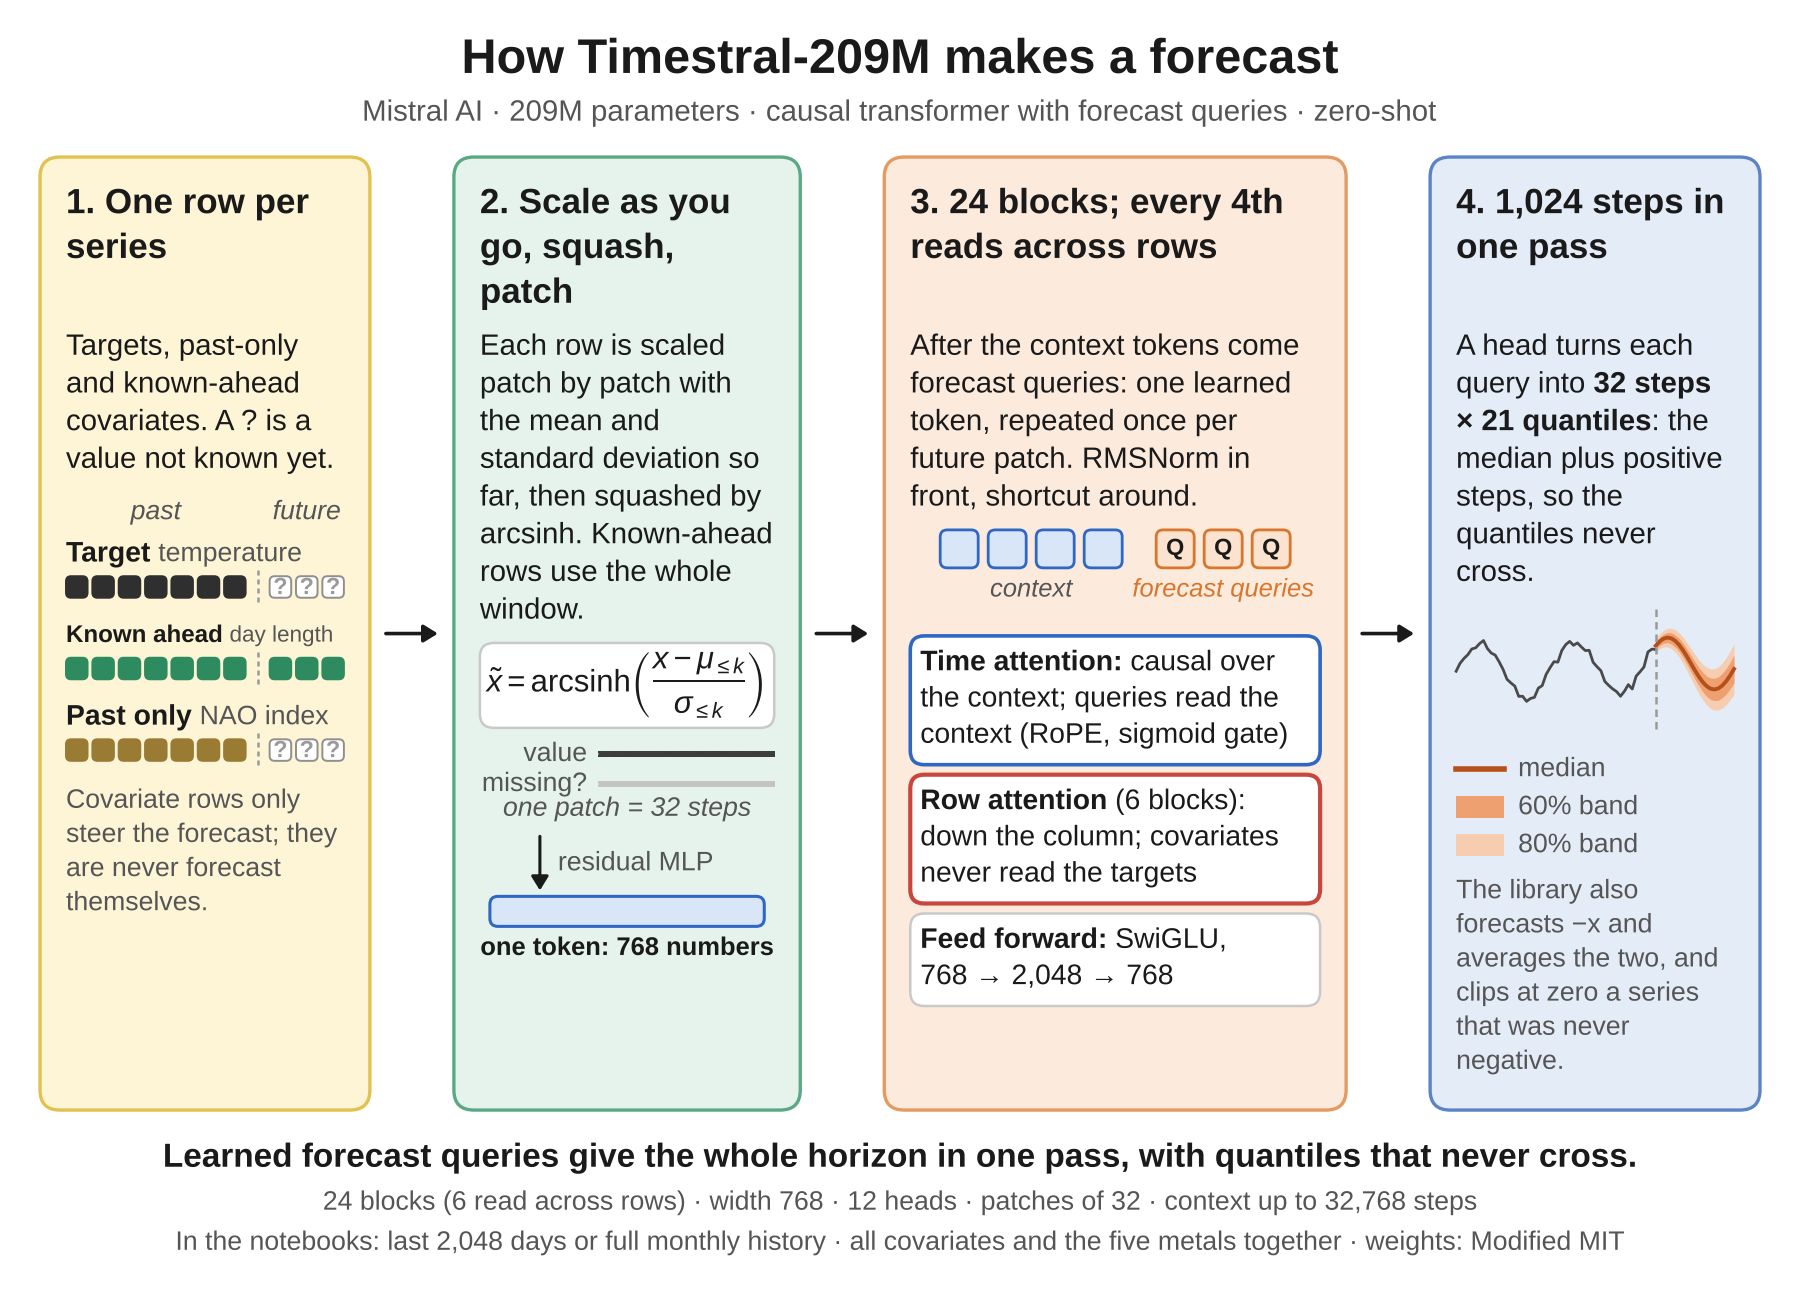

In [4]:
fig = figure("timestral", path=FIG / "timestral.png")

#### The maths behind the figure

The figure names the model's main components. Their equations follow, in the order in which the data passes through them.

The input is first **standardised** with the mean $\mu$ and standard deviation $\sigma$ of the context (in the causal versions, of the values seen so far), and then compressed with the **inverse hyperbolic sine** (arcsinh):

$$\tilde{x}_ t=\mathrm{arcsinh}\left(\frac{x_t-\mu}{\sigma}\right)$$

The arcsinh is close to a straight line near zero and grows like a logarithm for large values, so a few spikes cannot dominate the input.

**Patching** cuts the series into windows of $P$ steps, and each window becomes one token:

$$p_i=(\tilde{x}_ {(i-1)P+1},\dots,\tilde{x}_ {iP})$$

A context of $T$ steps then gives $T/P$ tokens, so attention costs $(T/P)^2$ instead of $T^2$.

The **quantile head** has one output per quantile level $\tau$. Training minimises the pinball loss $\rho_\tau$ of the error $u=y-\hat{q}_ \tau$:

$$\rho_\tau(u)=\max(\tau u,\thinspace(\tau-1)u)$$

Minimising this loss makes each output the $\tau$-quantile of the forecast distribution. The median ($\tau=0.5$) is the point forecast scored in this chapter.

**RMSNorm** divides each token vector $h$ by its root mean square and multiplies the result by a learned gain $g$:

$$\frac{h}{\sqrt{\frac{1}{d}\sum_j h_j^2+\epsilon}}\odot g$$

Here $d$ is the width of the vector and $\epsilon$ a small constant that avoids dividing by zero. The normalisation keeps the size of the activations stable through many layers.

**Gated attention** is scaled attention whose output is multiplied, element by element, by a sigmoid gate computed from the layer input $h$:

$$\sigma(hW_g)\odot\mathrm{softmax}\left(\frac{QK^{\top}}{\sqrt{d_k}}+M\right)V$$

Each head can thereby switch its own contribution off. The mask $M$ is causal in time attention and follows the role rules in variate attention: known-future covariates read only each other, and past-only covariates never read targets.

The **SwiGLU feed-forward network** passes one projection of the token through SiLU and uses it to gate a second projection, element by element ($\odot$), before projecting back:

$$W_2\left(\mathrm{SiLU}(W_1h)\odot W_3h\right)$$

It trains better than a plain ReLU network of the same size.

#### What it costs to run

Time attention costs O(V · N² · d) over N = (T + H)/32 tokens; attention across series runs in 6 of the 24 blocks. The loaded network has 209.3M parameters.

#### Covariates

Without fine-tuning, Timestral-209M can forecast several target series jointly and read both past-only and known-future covariates. Every fourth block attends across series, with masks that keep the covariates from reading the targets.

#### Where the figure comes from

The figure was checked against the model's paper, its released code and configuration, and the code this chapter
runs. The main sources for its components:

| Component in the figure | Source |
|---|---|
| causal encoder with Decoupled Horizon Forecasting (learned prediction tokens) | Mistral AI 2026, Sec. 3.1 and Fig. 5 |
| variate attention every 4th block, masking rules for covariates | Sec. 3.2 |
| patch 32 with missing indicators, residual MLP embedding; causal standardisation + asinh | Sec. 3.3 |
| pre-norm RMSNorm, SwiGLU, sigmoid-gated attention, RoPE on half head dims | Sec. 3.3; config |
| 21 quantiles: median plus softplus increments, 32 steps per token | Sec. 3.3 |
| d_model 768, 24 blocks, 12 heads, SwiGLU width 2048 | Table 1; config.json |

#### The code

This chapter's adapter for Timestral-209M is the class `Timestral` in [`src/ch03_zeroshot/models/timestral.py`](src/ch03_zeroshot/models/timestral.py) (line 31): it loads the checkpoint [`mistralai/Timestral-209M`](https://huggingface.co/mistralai/Timestral-209M), hands the model our context (and the covariates it can read) and turns its output into quantiles. All adapters share the interface `ZeroShotForecaster` in [`models/base.py`](src/ch03_zeroshot/models/base.py), and `run_model` in [`runner.py`](src/ch03_zeroshot/runner.py) runs it over every dataset, horizon and window. The network itself, layer by layer, is implemented in the `timestral` library, installed from [GitHub](https://github.com/mistralai/timestral) (pinned commit a534bdb). The figure above is drawn by [`architectures.py`](src/ch03_zeroshot/architectures.py).

In [5]:
forecast("timestral")

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Fetching 2 files: 100%|██████████| 2/2 [00:00<00:00, 644.78it/s]

Timestral-209M (mistralai/Timestral-209M): 209.3M parameters, loaded in 27.5 s


,status,seconds,covariates read,notes
dataset,,,,
D1,ran,0.6,none,
D2,ran,8.6,"fourier_sin_1, fourier_cos_1, fourier_sin_2, fourier_cos_2, daylength_h, wav_d1_2, wav_d3_4, wav_d5_6, wav_d7_8, wav_s8, nao, ao",
D3,ran,0.5,none,
D4,ran,1.3,"global_activity, usd, real_rate_10y",


## 2.2 · Timestral-5M (Mistral AI)

Timestral reads the context patches causally and forecasts through separate learned prediction tokens, a design its authors call Decoupled Horizon Forecasting, so a forecast of up to 32 patches needs a single forward pass. Every fourth block adds attention across series, with masks that keep covariates from seeing the targets. The quantiles are built as a median plus positive increments, so they can never cross.

#### How to read the figure

Read the figure from left to right. Its four numbered panels follow the data from the series the model reads to the forecast it returns. The bold sentence under the panels sums up what sets the model apart, and the grey lines below give its size and main settings, then how this chapter's notebooks run it.

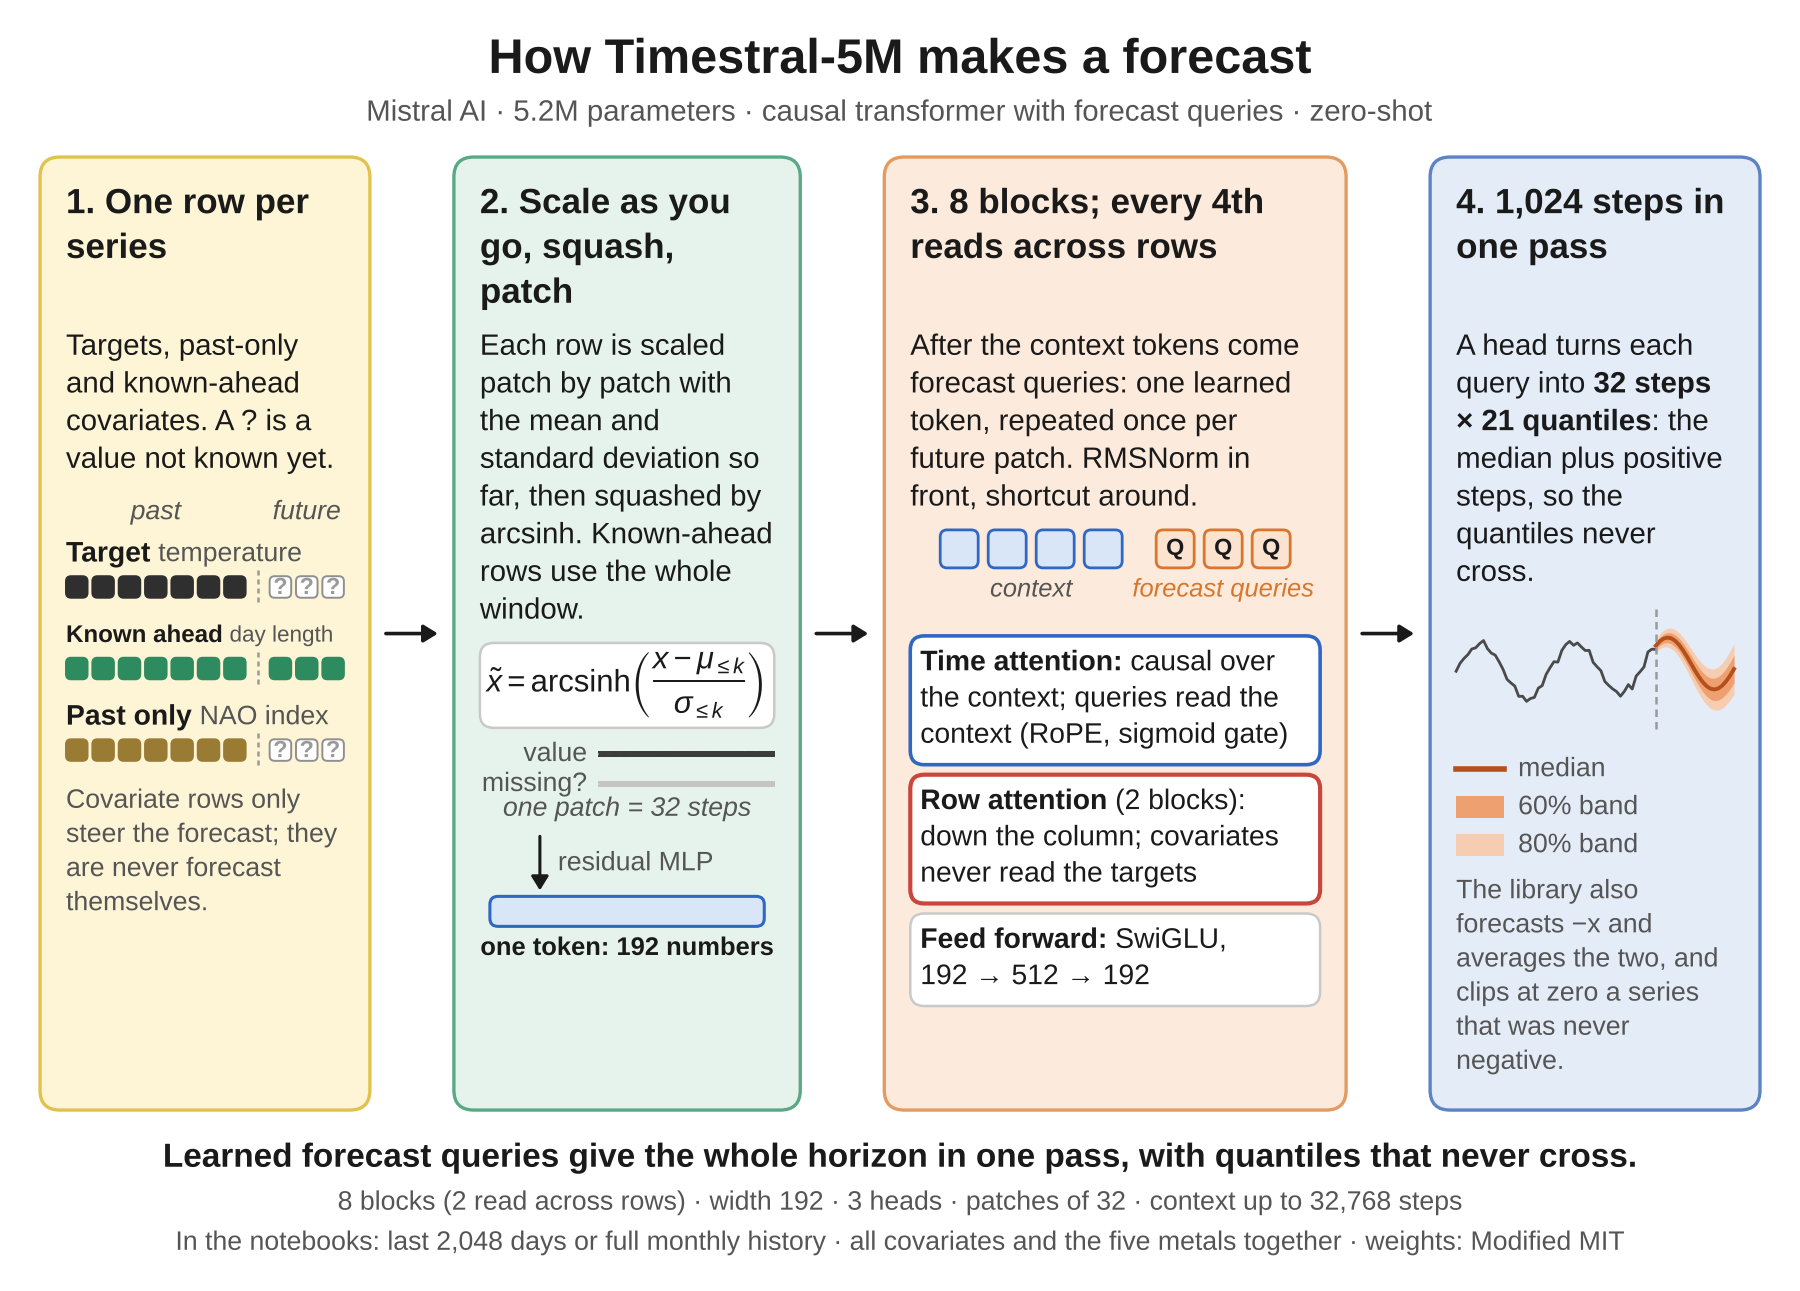

In [6]:
fig = figure("timestral-5m", path=FIG / "timestral-5m.png")

#### The maths behind the figure

The figure names the model's main components. Their equations follow, in the order in which the data passes through them.

The input is first **standardised** with the mean $\mu$ and standard deviation $\sigma$ of the context (in the causal versions, of the values seen so far), and then compressed with the **inverse hyperbolic sine** (arcsinh):

$$\tilde{x}_ t=\mathrm{arcsinh}\left(\frac{x_t-\mu}{\sigma}\right)$$

The arcsinh is close to a straight line near zero and grows like a logarithm for large values, so a few spikes cannot dominate the input.

**Patching** cuts the series into windows of $P$ steps, and each window becomes one token:

$$p_i=(\tilde{x}_ {(i-1)P+1},\dots,\tilde{x}_ {iP})$$

A context of $T$ steps then gives $T/P$ tokens, so attention costs $(T/P)^2$ instead of $T^2$.

The **quantile head** has one output per quantile level $\tau$. Training minimises the pinball loss $\rho_\tau$ of the error $u=y-\hat{q}_ \tau$:

$$\rho_\tau(u)=\max(\tau u,\thinspace(\tau-1)u)$$

Minimising this loss makes each output the $\tau$-quantile of the forecast distribution. The median ($\tau=0.5$) is the point forecast scored in this chapter.

**RMSNorm** divides each token vector $h$ by its root mean square and multiplies the result by a learned gain $g$:

$$\frac{h}{\sqrt{\frac{1}{d}\sum_j h_j^2+\epsilon}}\odot g$$

Here $d$ is the width of the vector and $\epsilon$ a small constant that avoids dividing by zero. The normalisation keeps the size of the activations stable through many layers.

**Gated attention** is scaled attention whose output is multiplied, element by element, by a sigmoid gate computed from the layer input $h$:

$$\sigma(hW_g)\odot\mathrm{softmax}\left(\frac{QK^{\top}}{\sqrt{d_k}}+M\right)V$$

Each head can thereby switch its own contribution off. The mask $M$ is causal in time attention and follows the role rules in variate attention: known-future covariates read only each other, and past-only covariates never read targets.

The **SwiGLU feed-forward network** passes one projection of the token through SiLU and uses it to gate a second projection, element by element ($\odot$), before projecting back:

$$W_2\left(\mathrm{SiLU}(W_1h)\odot W_3h\right)$$

It trains better than a plain ReLU network of the same size.

#### What it costs to run

Time attention costs O(V · N² · d) over N = (T + H)/32 tokens; attention across series runs in 2 of the 8 blocks. The loaded network has 5.2M parameters.

#### Covariates

Without fine-tuning, Timestral-5M can forecast several target series jointly and read both past-only and known-future covariates. Every fourth block attends across series, with masks that keep the covariates from reading the targets.

#### Where the figure comes from

The figure was checked against the model's paper, its released code and configuration, and the code this chapter
runs. The main sources for its components:

| Component in the figure | Source |
|---|---|
| causal encoder with Decoupled Horizon Forecasting (learned prediction tokens) | Mistral AI 2026, Sec. 3.1 and Fig. 5 |
| variate attention every 4th block, masking rules for covariates | Sec. 3.2 |
| patch 32 with missing indicators, residual MLP embedding; causal standardisation + asinh | Sec. 3.3 |
| pre-norm RMSNorm, SwiGLU, sigmoid-gated attention, RoPE on half head dims | Sec. 3.3; config |
| 21 quantiles: median plus softplus increments, 32 steps per token | Sec. 3.3 |
| d_model 192, 8 blocks, 3 heads, SwiGLU width 512 | Table 1; config.json |

#### The code

This chapter's adapter for Timestral-5M is the class `TimestralSmall` in [`src/ch03_zeroshot/models/timestral.py`](src/ch03_zeroshot/models/timestral.py) (line 94): it loads the checkpoint [`mistralai/Timestral-5M`](https://huggingface.co/mistralai/Timestral-5M), hands the model our context (and the covariates it can read) and turns its output into quantiles. All adapters share the interface `ZeroShotForecaster` in [`models/base.py`](src/ch03_zeroshot/models/base.py), and `run_model` in [`runner.py`](src/ch03_zeroshot/runner.py) runs it over every dataset, horizon and window. The network itself, layer by layer, is implemented in the `timestral` library, installed from [GitHub](https://github.com/mistralai/timestral) (pinned commit a534bdb). The figure above is drawn by [`architectures.py`](src/ch03_zeroshot/architectures.py).

In [7]:
forecast("timestral-5m")

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Fetching 2 files:  50%|█████     | 1/2 [00:00<00:00,  2.12it/s]

Fetching 2 files: 100%|██████████| 2/2 [00:00<00:00,  4.22it/s]

Timestral-5M (mistralai/Timestral-5M): 5.2M parameters, loaded in 0.9 s


,status,seconds,covariates read,notes
dataset,,,,
D1,ran,0.0,none,
D2,ran,0.4,"fourier_sin_1, fourier_cos_1, fourier_sin_2, fourier_cos_2, daylength_h, wav_d1_2, wav_d3_4, wav_d5_6, wav_d7_8, wav_s8, nao, ao",
D3,ran,0.1,none,
D4,ran,0.1,"global_activity, usd, real_rate_10y",


## 2.3 · TTM-r2 (IBM)

Tiny Time Mixers (TTM) have no attention and only one to a few million parameters. They are MLP-Mixer models: small fully connected networks mix the patches, first across time and then across features, and adaptive patching lets the model look at the context at several resolutions. IBM releases many checkpoints, each tied to one context length and horizon; the adapter picks the one for a 512-step context and the next horizon up.

#### How to read the figure

Read the figure from left to right. Its four numbered panels follow the data from the series the model reads to the forecast it returns. The bold sentence under the panels sums up what sets the model apart, and the grey lines below give its size and main settings, then how this chapter's notebooks run it.

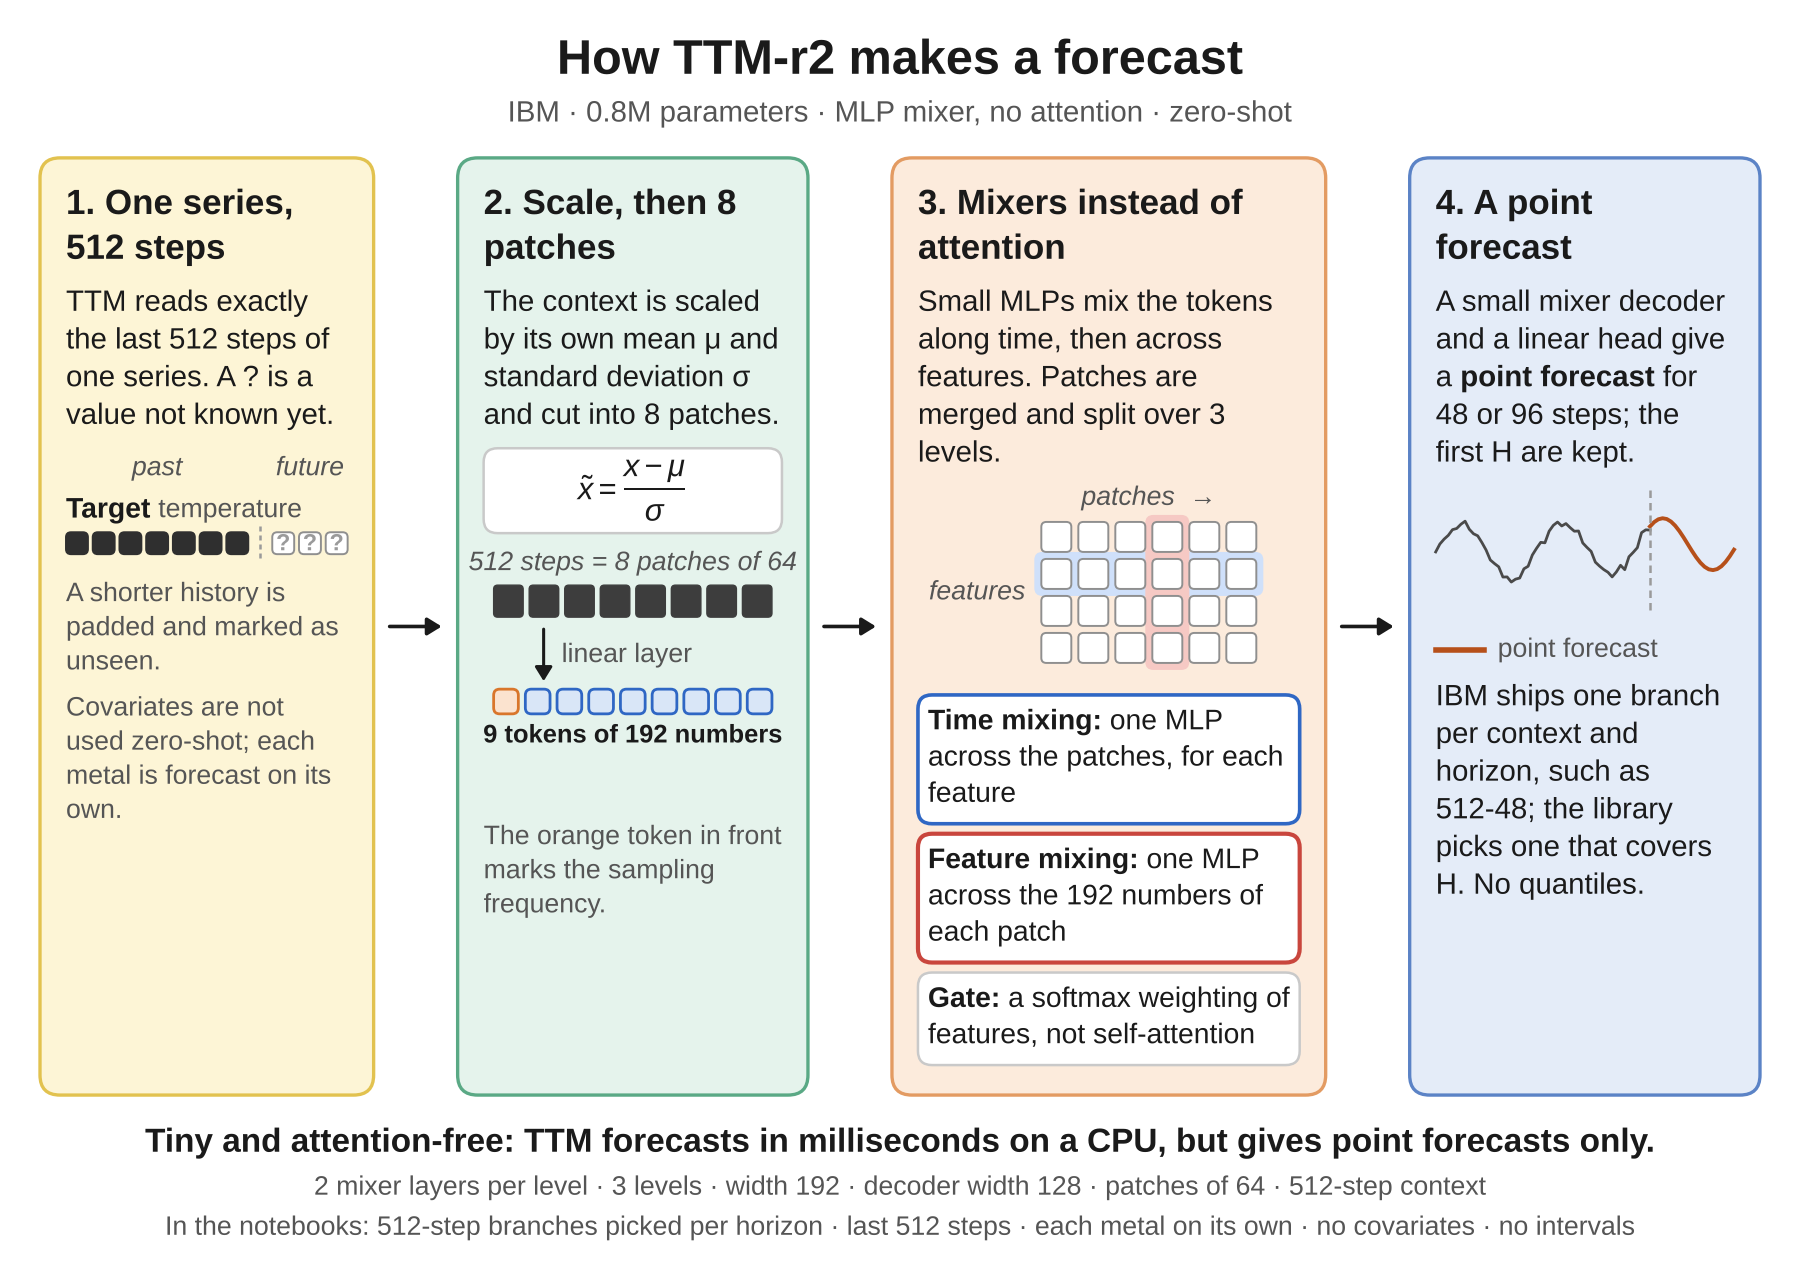

In [8]:
fig = figure("ttm", path=FIG / "ttm.png")

#### The maths behind the figure

The figure names the model's main components. Their equations follow, in the order in which the data passes through them.

**Instance normalisation** puts every series on the same scale, using the mean $\mu$ and standard deviation $\sigma$ of its own context (in the causal versions, of the values seen so far):

$$\tilde{x}_ t=\frac{x_t-\mu}{\sigma}$$

The forecast is mapped back to the original units with $x=\mu+\sigma\tilde{x}$.

**Patching** cuts the series into windows of $P$ steps, and each window becomes one token:

$$p_i=(\tilde{x}_ {(i-1)P+1},\dots,\tilde{x}_ {iP})$$

A context of $T$ steps then gives $T/P$ tokens, so attention costs $(T/P)^2$ instead of $T^2$.

The **linear embedding** maps each input token with one learned matrix $W$ to a vector of width $d$:

$$h_i=Wp_i+b$$

In most models the input token is a patch; in FlowState it is a single time step with its missing-value flag.

#### What it costs to run

Each mixer layer costs O(N · d²) with N = 8 patches, which makes TTM the cheapest model here. The loaded network has 0.8M parameters.

#### Covariates

Without fine-tuning, TTM-r2 reads no covariates: it forecasts each series on its own. TTM does have a mixer for covariates, but it only works after fine-tuning.

#### Where the figure comes from

The figure was checked against the model's paper, its released code and configuration, and the code this chapter
runs. The main sources for its components:

| Component in the figure | Source |
|---|---|
| TSMixer backbone, adaptive patching, resolution prefix tuning, small decoder, linear head | Ekambaram et al. 2024, Sec. 2-3.1 and Fig. 2 |
| exogenous mixer used in fine-tuning | Sec. 3.2 |
| context 512, patch 64, d_model 192, 2 layers, adaptive levels 3, decoder d_model 128, 2 layers | config.json (main revision) |
| revision chosen per horizon, e.g. 512-48-ft-r2.1 | granite-tsfm 0.3.10 get_model log |

#### The code

This chapter's adapter for TTM-r2 is the class `TTM` in [`src/ch03_zeroshot/models/ibm.py`](src/ch03_zeroshot/models/ibm.py) (line 69): it loads the checkpoint [`ibm-granite/granite-timeseries-ttm-r2`](https://huggingface.co/ibm-granite/granite-timeseries-ttm-r2), hands the model our context (and the covariates it can read) and turns its output into quantiles. All adapters share the interface `ZeroShotForecaster` in [`models/base.py`](src/ch03_zeroshot/models/base.py), and `run_model` in [`runner.py`](src/ch03_zeroshot/runner.py) runs it over every dataset, horizon and window. The network itself, layer by layer, is implemented in the `granite-tsfm` 0.3.10 library ([PyPI page](https://pypi.org/project/granite-tsfm/0.3.10/)). The figure above is drawn by [`architectures.py`](src/ch03_zeroshot/architectures.py).

In [9]:
forecast("ttm")

Loading weights:   0%|          | 0/139 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 139/139 [00:00<00:00, 1578.69it/s]

Loading weights:   0%|          | 0/139 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 139/139 [00:00<00:00, 3863.11it/s]

Loading weights:   0%|          | 0/139 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 139/139 [00:00<00:00, 3303.22it/s]

Loading weights:   0%|          | 0/139 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 139/139 [00:00<00:00, 3311.78it/s]

TTM-r2 (ibm-granite/granite-timeseries-ttm-r2): 0.8M parameters, loaded in 0.0 s


,status,seconds,covariates read,notes
dataset,,,,
D1,ran,5.6,none,
D2,D1 forecasts reused,0.0,none,"reads none of these covariates, so its input is exactly D1's"
D3,ran,0.4,none,
D4,D3 forecasts reused,0.0,none,"reads none of these covariates, so its input is exactly D3's"


## 2.4 · FlowState-r1.1 (IBM)

FlowState replaces the transformer with an S5 state-space encoder that runs over every time step, and its decoder outputs the coefficients of a smooth function of time (a sum of Legendre polynomials) instead of values at fixed steps. Scaling the step size of the state-space layer and the decoder's sampling step to the data makes the model sampling-rate equivariant: one set of weights serves hourly, daily or monthly data.

#### How to read the figure

Read the figure from left to right. Its four numbered panels follow the data from the series the model reads to the forecast it returns. The bold sentence under the panels sums up what sets the model apart, and the grey lines below give its size and main settings, then how this chapter's notebooks run it.

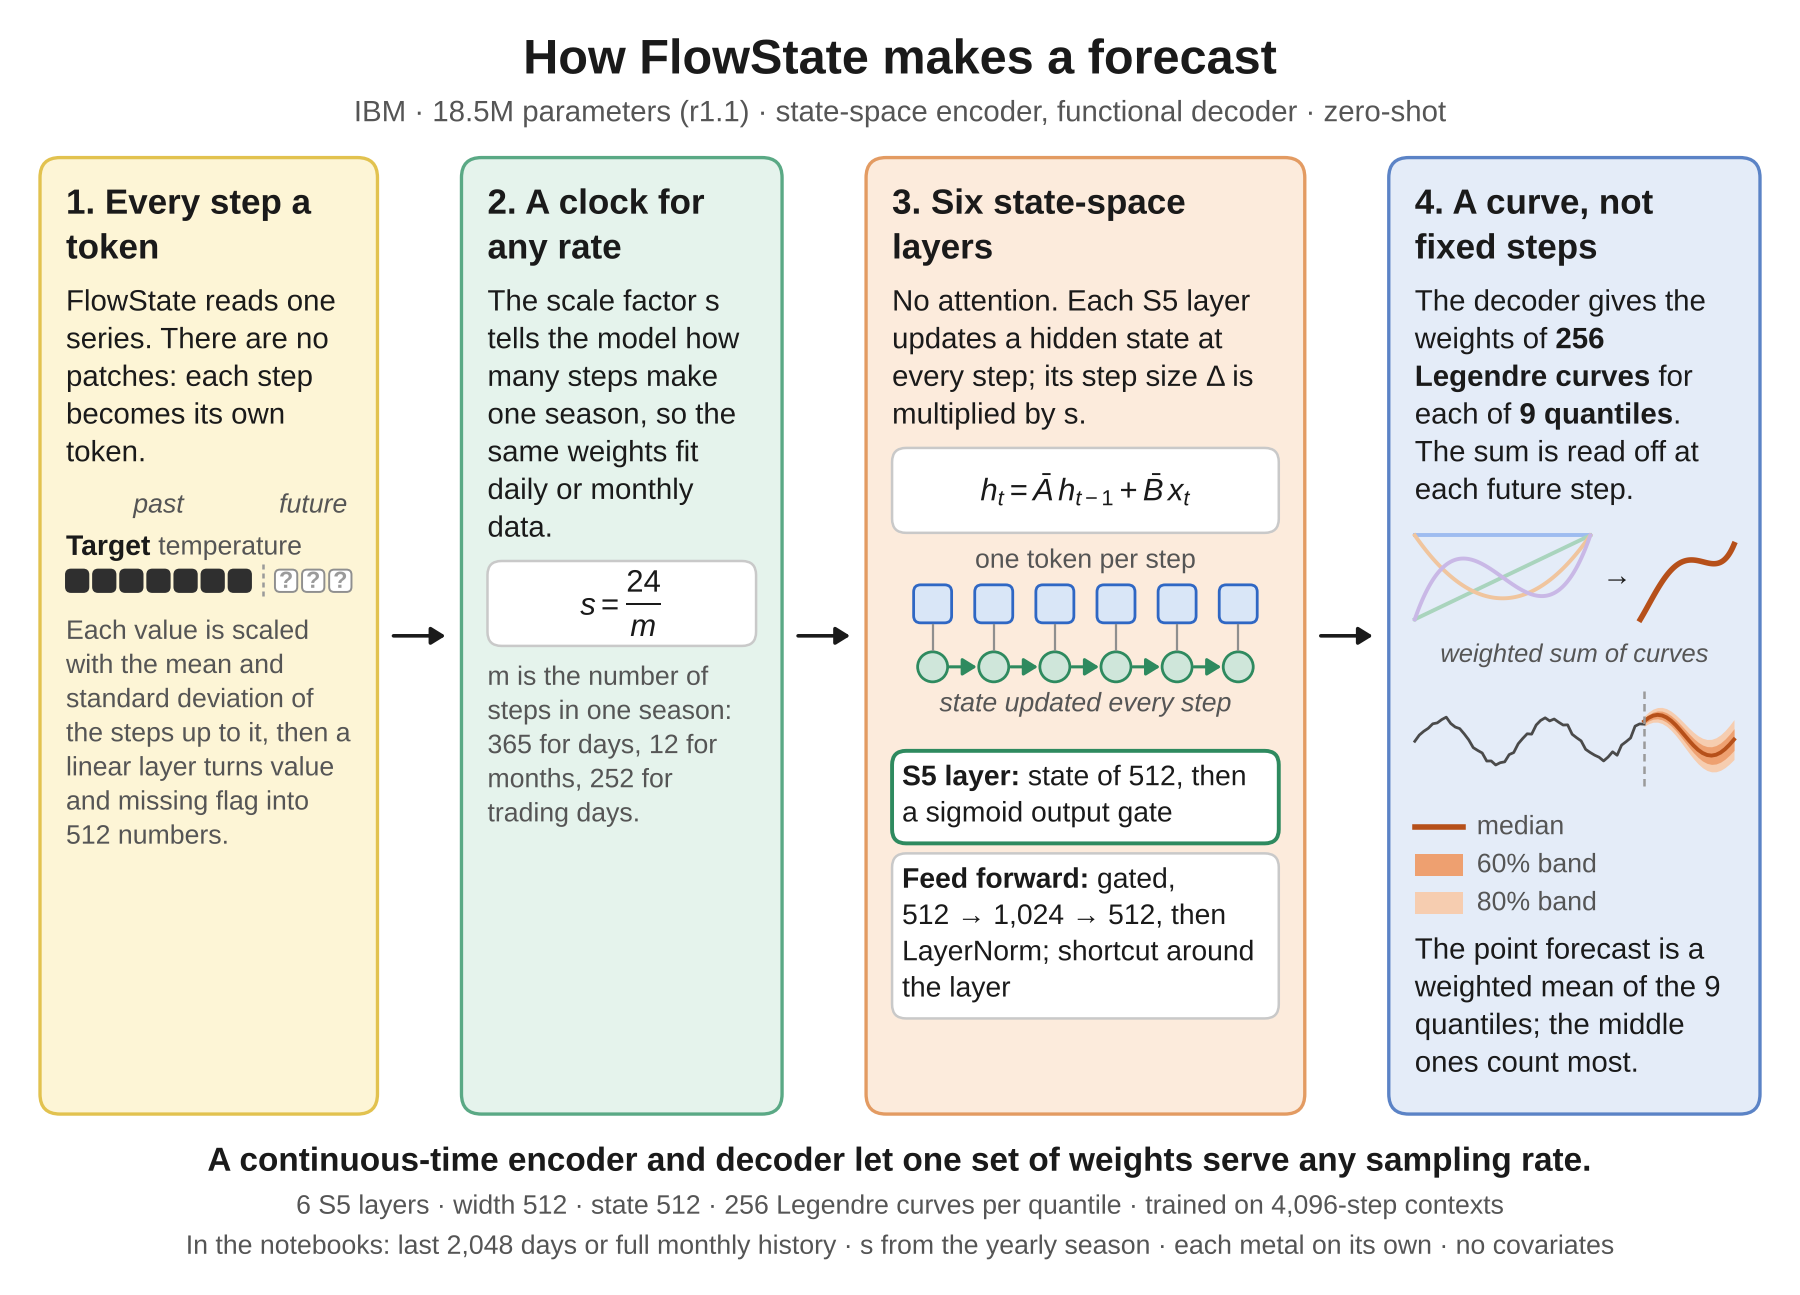

In [10]:
fig = figure("flowstate", path=FIG / "flowstate.png")

#### The maths behind the figure

The figure names the model's main components. Their equations follow, in the order in which the data passes through them.

**Instance normalisation** puts every series on the same scale, using the mean $\mu$ and standard deviation $\sigma$ of its own context (in the causal versions, of the values seen so far):

$$\tilde{x}_ t=\frac{x_t-\mu}{\sigma}$$

The forecast is mapped back to the original units with $x=\mu+\sigma\tilde{x}$.

The **linear embedding** maps each input token with one learned matrix $W$ to a vector of width $d$:

$$h_i=Wp_i+b$$

In most models the input token is a patch; in FlowState it is a single time step with its missing-value flag.

The **functional decoder** outputs a smooth function of time, a weighted sum of Legendre polynomials $P_n$ whose coefficients $c_n$ come from the network:

$$\hat{y}(t)=\sum_{n}c_n\thinspace P_n(t)$$

The forecast can therefore be read at any horizon.

A **state-space layer** updates a hidden state $s_k$ linearly from the previous state and the new input $u_k$, and reads its output $y_k$ from the state:

$$s_k=\bar{A}s_{k-1}+\bar{B}u_k,\ \ y_k=Cs_k+Du_k$$

The discretised matrices $\bar{A}$ and $\bar{B}$ depend on the step size, which FlowState scales with the sampling rate.

**RMSNorm** divides each token vector $h$ by its root mean square and multiplies the result by a learned gain $g$:

$$\frac{h}{\sqrt{\frac{1}{d}\sum_j h_j^2+\epsilon}}\odot g$$

Here $d$ is the width of the vector and $\epsilon$ a small constant that avoids dividing by zero. The normalisation keeps the size of the activations stable through many layers.

The **SwiGLU feed-forward network** passes one projection of the token through SiLU and uses it to gate a second projection, element by element ($\odot$), before projecting back:

$$W_2\left(\mathrm{SiLU}(W_1h)\odot W_3h\right)$$

It trains better than a plain ReLU network of the same size.

**LayerNorm** centres each token vector $h$ on its mean $\bar{h}$, divides it by its standard deviation $s_h$, and then rescales and shifts it with the learned $g$ and $b$:

$$\frac{h-\bar{h}}{s_h}\odot g+b$$

#### What it costs to run

The cost is linear in the context length, O(L · T · d), computed with parallel scans; there is no attention. The loaded network has 18.5M parameters.

#### Covariates

Without fine-tuning, FlowState-r1.1 reads no covariates: it forecasts each series on its own.

#### Where the figure comes from

The figure was checked against the model's paper, its released code and configuration, and the code this chapter
runs. The main sources for its components:

| Component in the figure | Source |
|---|---|
| linear embedding without patching, S5 encoder, functional basis decoder | Graf et al. 2025, Sec. 3 and Fig. 1 |
| causal normalisation | Sec. 5.1 |
| sampling-rate scale factors for encoder and decoder | Sec. 3.3 |
| S5 block with sigmoid output gate, then a two-layer gated MLP (expansion 2) and LayerNorm, all inside a skip | Sec. 3.1, App. (18.6M variant); granite-tsfm FlowStateS5Layer |
| 6 S5 layers, state 512, embedding 512, Legendre ('legs') decoder 256, 9 quantiles | config.json; module tree |
| decoder Linear 512 → 2304 = 256 × 9 | module tree |

#### The code

This chapter's adapter for FlowState-r1.1 is the class `FlowState` in [`src/ch03_zeroshot/models/ibm.py`](src/ch03_zeroshot/models/ibm.py) (line 129): it loads the checkpoint [`ibm-granite/granite-timeseries-flowstate-r1`](https://huggingface.co/ibm-granite/granite-timeseries-flowstate-r1), hands the model our context (and the covariates it can read) and turns its output into quantiles. All adapters share the interface `ZeroShotForecaster` in [`models/base.py`](src/ch03_zeroshot/models/base.py), and `run_model` in [`runner.py`](src/ch03_zeroshot/runner.py) runs it over every dataset, horizon and window. The network itself, layer by layer, is implemented in the `granite-tsfm` 0.3.10 library ([PyPI page](https://pypi.org/project/granite-tsfm/0.3.10/)). The figure above is drawn by [`architectures.py`](src/ch03_zeroshot/architectures.py).

In [11]:
forecast("flowstate")

[transformers] `use_return_dict` is deprecated! Use `return_dict` instead!


Loading weights:   0%|          | 0/118 [00:00<?, ?it/s]

Loading weights:  11%|█         | 13/118 [00:00<00:01, 101.72it/s]

Loading weights:  20%|██        | 24/118 [00:00<00:01, 74.46it/s] 

Loading weights:  27%|██▋       | 32/118 [00:00<00:01, 50.66it/s]

Loading weights:  32%|███▏      | 38/118 [00:00<00:02, 37.68it/s]

... (5 outputs left out)

Loading weights:  75%|███████▌  | 89/118 [00:01<00:00, 56.13it/s]

Loading weights: 100%|██████████| 118/118 [00:01<00:00, 66.56it/s]

FlowState-r1.1 (ibm-granite/granite-timeseries-flowstate-r1): 18.5M parameters, loaded in 2.3 s


,status,seconds,covariates read,notes
dataset,,,,
D1,ran,2.7,none,
D2,D1 forecasts reused,0.0,none,"reads none of these covariates, so its input is exactly D1's"
D3,ran,1.0,none,
D4,D3 forecasts reused,0.0,none,"reads none of these covariates, so its input is exactly D3's"


#### FlowState's one setting: the time scale

FlowState's state-space encoder and functional decoder work in continuous time, so the model has to be told how
many steps make one cycle. The model card gives the rule

$$\text{scale factor} = \frac{24}{N}$$

for data that repeat every $N$ steps, where 24 is the cycle the model mostly saw in pre-training (one day of hourly
data). Its table recommends 2 for monthly data, a yearly cycle of 12 months, and 0.0656 for daily data without a
weekly cycle, a yearly cycle of about 365 days. `run_model` applies the rule to one year of steps from `YEAR_STEPS`
in the data module: 24/365 ≈ 0.0658 for D1 and D2, 24/12 = 2 for D3 and D4, and 24/252 ≈ 0.0952 for B1 and B2
(252 trading days a year).

The cell below forecasts five windows of one horizon twice, once with the hourly default and once with the yearly
setting (under a minute on a CPU). The windows are validation windows: they sit back to back and end at the
earliest test origin, so they lie inside the training data and no test value plays any part in the comparison
(`validation_rows` in the data module).

In [12]:
from ch03_zeroshot.runner import flowstate_scale_check

flowstate_scale_check(ROOT, cases=(("D1", 30), ("D3", 12)))

Loading weights:   0%|          | 0/118 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 118/118 [00:00<00:00, 3515.34it/s]

scale factor  forecasts        validation windows       MAE
dataset horizon cycle                                                                                 
D1      30      hourly default (24 steps)        1.0000          5  2025-02-08 to 2025-07-07     3.038
                one year (365 steps)             0.0658          5  2025-02-08 to 2025-07-07     2.194
D3      12      hourly default (24 steps)        1.0000         25  2018-08-01 to 2023-07-01  1057.231
                one year (12 steps)              2.0000         25  2018-08-01 to 2023-07-01   904.409

With the hourly default FlowState reads one year of daily temperature as about fifteen daily cycles, and its MAE at
30 days is 38% higher on the validation windows (17% higher on metals at 12 months). The setting itself comes from
the model card, not from these numbers: the check only confirms, on past data, that the card's advice holds here.
With it FlowState's mean MASE on the D1 test windows is 0.678, level with the best models of Notebook 05a.
Zero-shot does not mean setting-free: a model's documented inputs (here the time scale, for
TTM the frequency token, for Lag-Llama the calendar dates) are part of using it correctly.

## 2.5 · PatchTST-FM-r2 (IBM)

PatchTST-FM scales up the PatchTST idea (patches as tokens, one series at a time) into a foundation model. Its Conformer blocks place attention and a depthwise convolution between two half-step feed-forward layers, and it forecasts by reconstructing masked future patches. Overlapping patches are blended back together with a Hamming window.

#### How to read the figure

Read the figure from left to right. Its four numbered panels follow the data from the series the model reads to the forecast it returns. The bold sentence under the panels sums up what sets the model apart, and the grey lines below give its size and main settings, then how this chapter's notebooks run it.

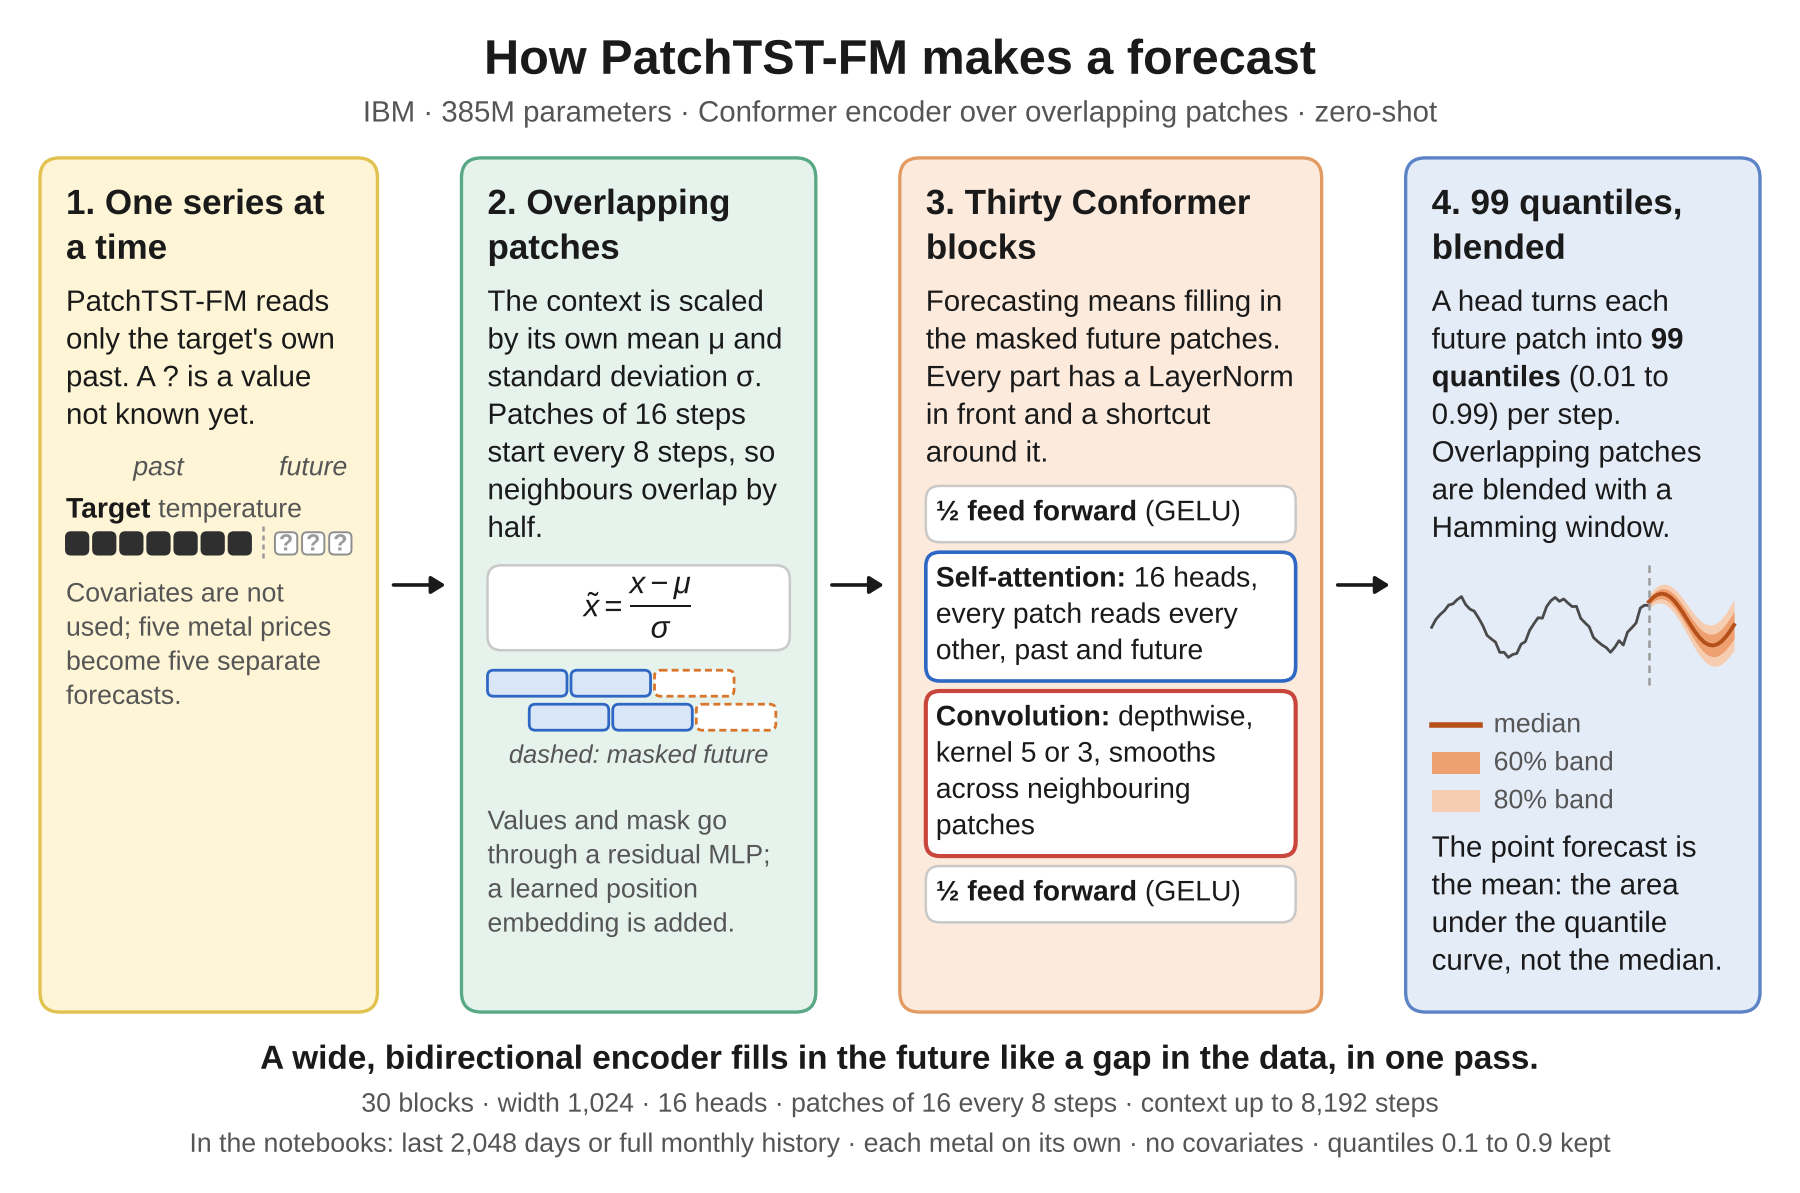

In [13]:
fig = figure("patchtst-fm", path=FIG / "patchtst-fm.png")

#### The maths behind the figure

The figure names the model's main components. Their equations follow, in the order in which the data passes through them.

**Instance normalisation** puts every series on the same scale, using the mean $\mu$ and standard deviation $\sigma$ of its own context (in the causal versions, of the values seen so far):

$$\tilde{x}_ t=\frac{x_t-\mu}{\sigma}$$

The forecast is mapped back to the original units with $x=\mu+\sigma\tilde{x}$.

**Patching** cuts the series into windows of $P$ steps, and each window becomes one token:

$$p_i=(\tilde{x}_ {(i-1)P+1},\dots,\tilde{x}_ {iP})$$

A context of $T$ steps then gives $T/P$ tokens, so attention costs $(T/P)^2$ instead of $T^2$.

The **patch embedding** turns each patch (with its missing-value mask, where the model has one) into a vector of width $d$, the token the transformer works on:

$$h_i=\mathrm{MLP}(p_i)$$

The map is a small fully connected network, a multilayer perceptron (MLP).

**LayerNorm** centres each token vector $h$ on its mean $\bar{h}$, divides it by its standard deviation $s_h$, and then rescales and shifts it with the learned $g$ and $b$:

$$\frac{h-\bar{h}}{s_h}\odot g+b$$

The **feed-forward network** applies the smooth GELU activation between two projections, to every token separately:

$$W_2\thinspace\mathrm{GELU}(W_1h)$$

**Scaled dot-product attention** compares each token's query $Q$ with the keys $K$ of the tokens it may read, and a softmax turns the scores into weights that mix their values $V$:

$$\mathrm{softmax}\left(\frac{QK^{\top}}{\sqrt{d_k}}\right)V$$

Every token is thus rebuilt from the tokens that matter for it.

#### What it costs to run

O(L · N² · d) with N ≈ (T + H)/8 overlapping patches and L = 30 wide layers, which makes it the heaviest model here. The loaded network has 384.6M parameters.

#### Covariates

Without fine-tuning, PatchTST-FM-r2 reads no covariates: it forecasts each series on its own.

#### Where the figure comes from

The figure was checked against the model's paper, its released code and configuration, and the code this chapter
runs. The main sources for its components:

| Component in the figure | Source |
|---|---|
| conformer blocks: half FFN, MHSA, conv, half FFN | model card ibm-granite/granite-timeseries-patchtst-fm-r2 |
| 30 layers, d_model 1024, 16 heads, patch 16 stride 8, 99 quantiles, context 8192 | config.json |
| non-causal, Hamming patch-loss windowing, pre-head norm | config.json |
| depthwise Conv2d kernels (1,5)/(1,3), RevIN, residual in/out layers | module tree |

#### The code

This chapter's adapter for PatchTST-FM-r2 is the class `PatchTSTFM` in [`src/ch03_zeroshot/models/ibm.py`](src/ch03_zeroshot/models/ibm.py) (line 171): it loads the checkpoint [`ibm-granite/granite-timeseries-patchtst-fm-r2`](https://huggingface.co/ibm-granite/granite-timeseries-patchtst-fm-r2), hands the model our context (and the covariates it can read) and turns its output into quantiles. All adapters share the interface `ZeroShotForecaster` in [`models/base.py`](src/ch03_zeroshot/models/base.py), and `run_model` in [`runner.py`](src/ch03_zeroshot/runner.py) runs it over every dataset, horizon and window. The network itself, layer by layer, is implemented in the `granite-tsfm` 0.3.10 library ([PyPI page](https://pypi.org/project/granite-tsfm/0.3.10/)). The figure above is drawn by [`architectures.py`](src/ch03_zeroshot/architectures.py).

In [14]:
forecast("patchtst-fm")

Loading weights:   0%|          | 0/646 [00:00<?, ?it/s]

Loading weights:   2%|▏         | 10/646 [00:00<00:13, 48.70it/s]

Loading weights:   2%|▏         | 15/646 [00:00<00:17, 35.49it/s]

Loading weights:   3%|▎         | 19/646 [00:00<00:22, 27.81it/s]

Loading weights:   3%|▎         | 22/646 [00:00<00:30, 20.78it/s]

Loading weights:   4%|▍         | 25/646 [00:01<00:34, 17.89it/s]

... (74 outputs left out)

Loading weights:  65%|██████▌   | 421/646 [00:16<00:07, 29.33it/s]

Loading weights: 100%|██████████| 646/646 [00:16<00:00, 40.18it/s]

PatchTST-FM-r2 (ibm-granite/granite-timeseries-patchtst-fm-r2): 384.6M parameters, loaded in 17.3 s


,status,seconds,covariates read,notes
dataset,,,,
D1,ran,29.2,none,
D2,D1 forecasts reused,0.0,none,"reads none of these covariates, so its input is exactly D1's"
D3,ran,1.7,none,
D4,D3 forecasts reused,0.0,none,"reads none of these covariates, so its input is exactly D3's"


## 2.6 · t0-gamma (The Forecasting Company)

t0 is a decoder-style patch transformer whose layers repeat a pattern of two time-attention layers and one variate-attention layer. A learned role embedding tells the model whether a row is a target, a past-only covariate or a known-future covariate, and the attention masks follow those roles. The t0 report describes the alpha and beta checkpoints; t0-gamma is a larger, later member of the family.

#### How to read the figure

Read the figure from left to right. Its four numbered panels follow the data from the series the model reads to the forecast it returns. The bold sentence under the panels sums up what sets the model apart, and the grey lines below give its size and main settings, then how this chapter's notebooks run it.

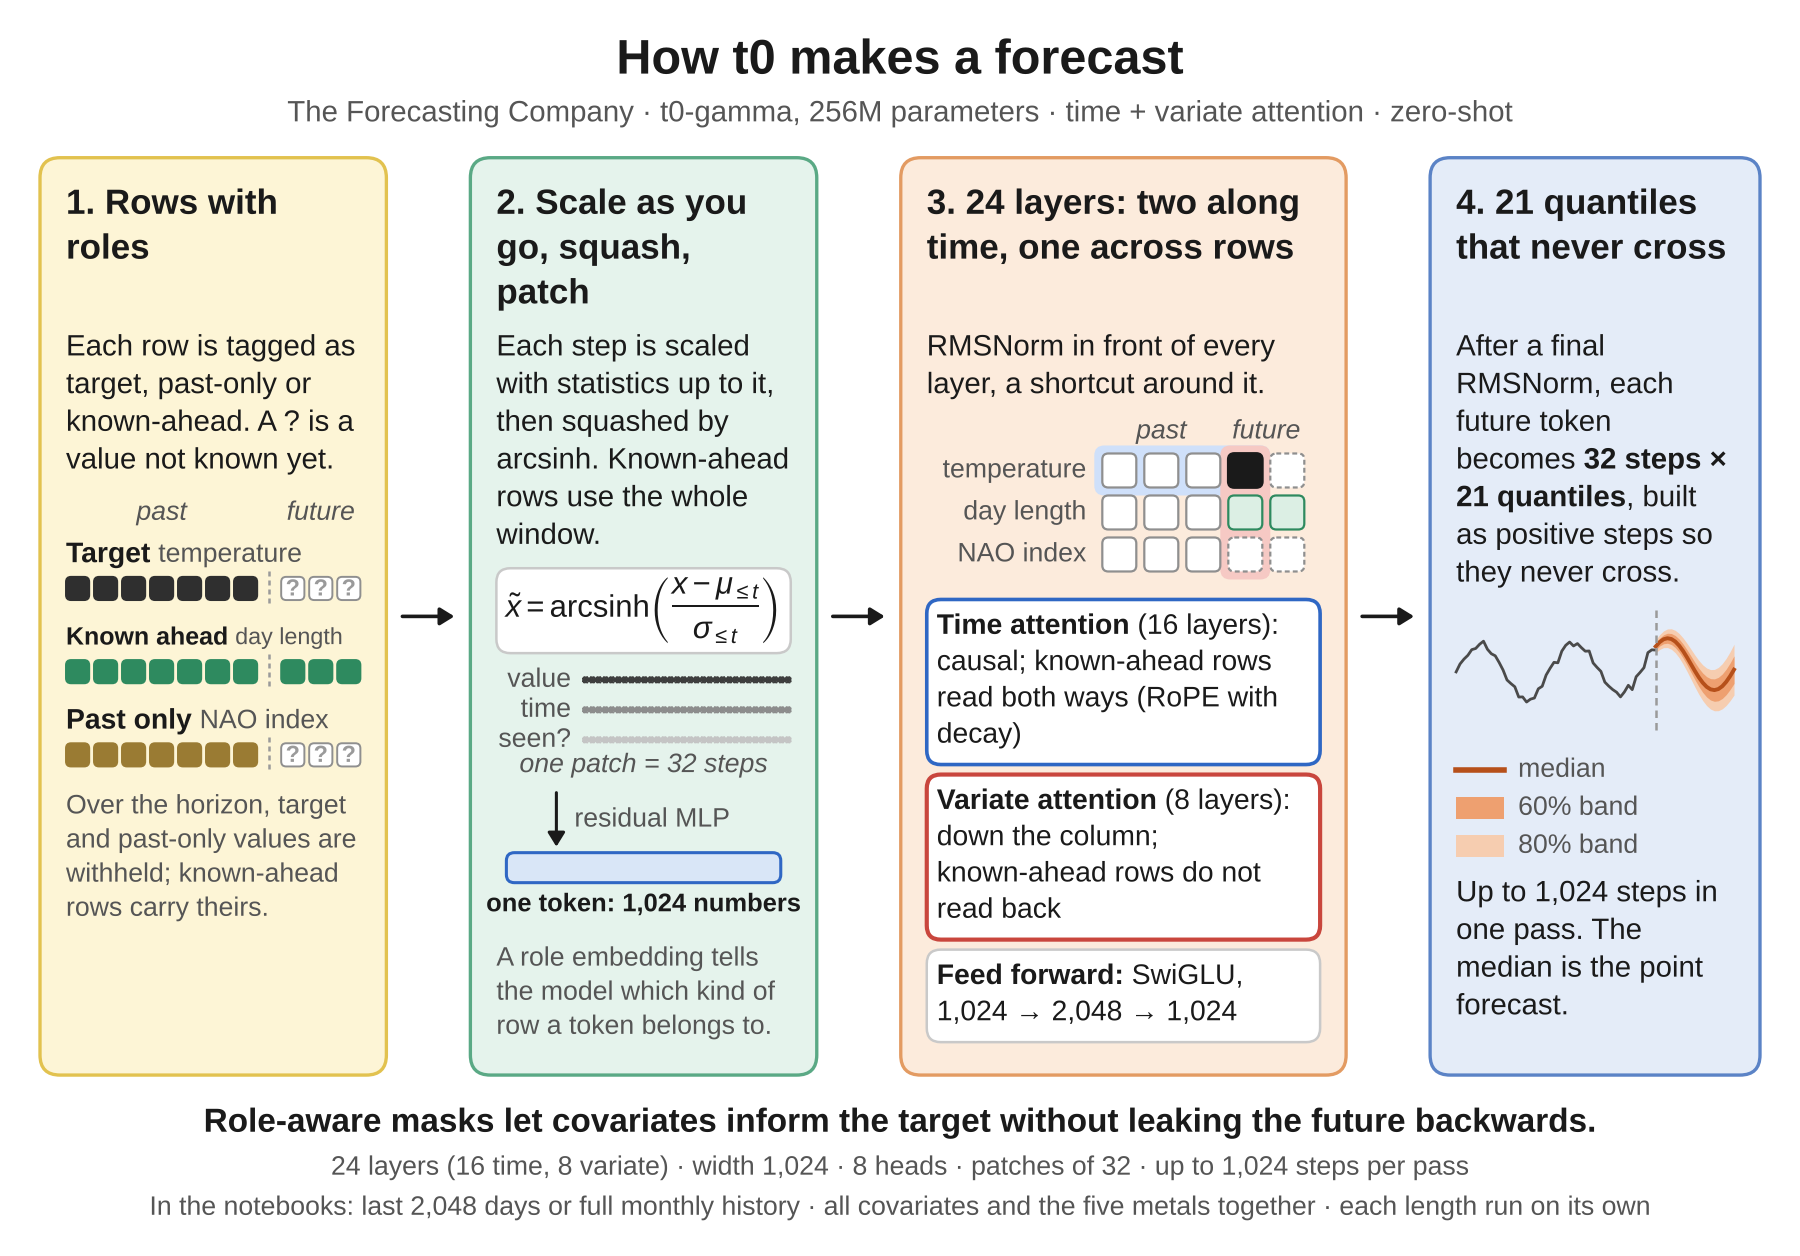

In [15]:
fig = figure("t0", path=FIG / "t0.png")

#### The maths behind the figure

The figure names the model's main components. Their equations follow, in the order in which the data passes through them.

The input is first **standardised** with the mean $\mu$ and standard deviation $\sigma$ of the context (in the causal versions, of the values seen so far), and then compressed with the **inverse hyperbolic sine** (arcsinh):

$$\tilde{x}_ t=\mathrm{arcsinh}\left(\frac{x_t-\mu}{\sigma}\right)$$

The arcsinh is close to a straight line near zero and grows like a logarithm for large values, so a few spikes cannot dominate the input.

**Patching** cuts the series into windows of $P$ steps, and each window becomes one token:

$$p_i=(\tilde{x}_ {(i-1)P+1},\dots,\tilde{x}_ {iP})$$

A context of $T$ steps then gives $T/P$ tokens, so attention costs $(T/P)^2$ instead of $T^2$.

**RMSNorm** divides each token vector $h$ by its root mean square and multiplies the result by a learned gain $g$:

$$\frac{h}{\sqrt{\frac{1}{d}\sum_j h_j^2+\epsilon}}\odot g$$

Here $d$ is the width of the vector and $\epsilon$ a small constant that avoids dividing by zero. The normalisation keeps the size of the activations stable through many layers.

**Masked self-attention** compares each token's query $Q$ with the keys $K$, turns the scores into weights with a softmax, and uses the weights to mix the values $V$:

$$\mathrm{softmax}\left(\frac{QK^{\top}}{\sqrt{d_k}}+M\right)V$$

The mask $M$ is $-\infty$ wherever a token may not read another: a later time step in causal attention, or an excluded pair in variate attention (covariates that may not read targets, or rows that belong to different series). Dividing by $\sqrt{d_k}$, the square root of the key width, keeps the scores in a range where the softmax does not saturate.

The **SwiGLU feed-forward network** passes one projection of the token through SiLU and uses it to gate a second projection, element by element ($\odot$), before projecting back:

$$W_2\left(\mathrm{SiLU}(W_1h)\odot W_3h\right)$$

It trains better than a plain ReLU network of the same size.

#### What it costs to run

The time layers cost O(V · N² · d) and the variate layers O(N · V² · d), with N = (T + H)/32. The loaded network has 255.6M parameters.

#### Covariates

Without fine-tuning, t0-gamma can forecast several target series jointly and read both past-only and known-future covariates. Time attention and variate attention alternate, and the known-future rows are read in both directions.

#### Where the figure comes from

The figure was checked against the model's paper, its released code and configuration, and the code this chapter
runs. The main sources for its components:

| Component in the figure | Source |
|---|---|
| decoder-style patch transformer, decoupled time and variate attention | Meyer et al. 2026, Sec. 4.1 |
| causal scaling + arcsinh; known-future scaled over the whole span | Sec. 4.1 Eq. 2 |
| embedding: values, within-patch time index, mask; role embedding | Sec. 4.1 |
| pattern 2 time layers then 1 variate layer; asymmetric variate attention | Sec. 4.1 |
| monotone quantiles via softplus increments; single pass up to 1024 steps | Sec. 4.1, 4.3 |
| RoPE with xPos decay by patch position; pre-norm RMSNorm, QK-norm, SwiGLU | Sec. 4.1, Table 2 |
| the t0 report details t0-alpha (width 512, 102M); t0-gamma is the larger release: 24 layers, embed 1024, 8 heads, FFN 2048, patch 32, group_every_n 3, 21 quantiles | config.json; module tree |

#### The code

This chapter's adapter for t0-gamma is the class `T0` in [`src/ch03_zeroshot/models/others.py`](src/ch03_zeroshot/models/others.py) (line 36): it loads the checkpoint [`theforecastingcompany/t0-gamma`](https://huggingface.co/theforecastingcompany/t0-gamma), hands the model our context (and the covariates it can read) and turns its output into quantiles. All adapters share the interface `ZeroShotForecaster` in [`models/base.py`](src/ch03_zeroshot/models/base.py), and `run_model` in [`runner.py`](src/ch03_zeroshot/runner.py) runs it over every dataset, horizon and window. The network itself, layer by layer, is implemented in the `tfc-t0` 0.6.0 library ([PyPI page](https://pypi.org/project/tfc-t0/0.6.0/)). The figure above is drawn by [`architectures.py`](src/ch03_zeroshot/architectures.py).

In [16]:
forecast("t0")

t0-gamma (theforecastingcompany/t0-gamma): 255.6M parameters, loaded in 27.2 s


,status,seconds,covariates read,notes
dataset,,,,
D1,ran,0.3,none,
D2,ran,1.9,"fourier_sin_1, fourier_cos_1, fourier_sin_2, fourier_cos_2, daylength_h, wav_d1_2, wav_d3_4, wav_d5_6, wav_d7_8, wav_s8, nao, ao",
D3,ran,0.4,none,
D4,ran,0.5,"global_activity, usd, real_rate_10y",


## 2.7 · TabPFN-TS (v2 weights) (Prior Labs)

TabPFN-TS turns forecasting into filling in a table. Each time step becomes a row with time features (a running index, calendar terms and automatically detected seasonal terms) and any known-future covariates. TabPFN-v2, a transformer pre-trained on synthetic tables, then predicts the target in the horizon rows from the context rows, in one pass.

#### How to read the figure

Read the figure from left to right. Its four numbered panels follow the data from the series the model reads to the forecast it returns. The bold sentence under the panels sums up what sets the model apart, and the grey lines below give its size and main settings, then how this chapter's notebooks run it.

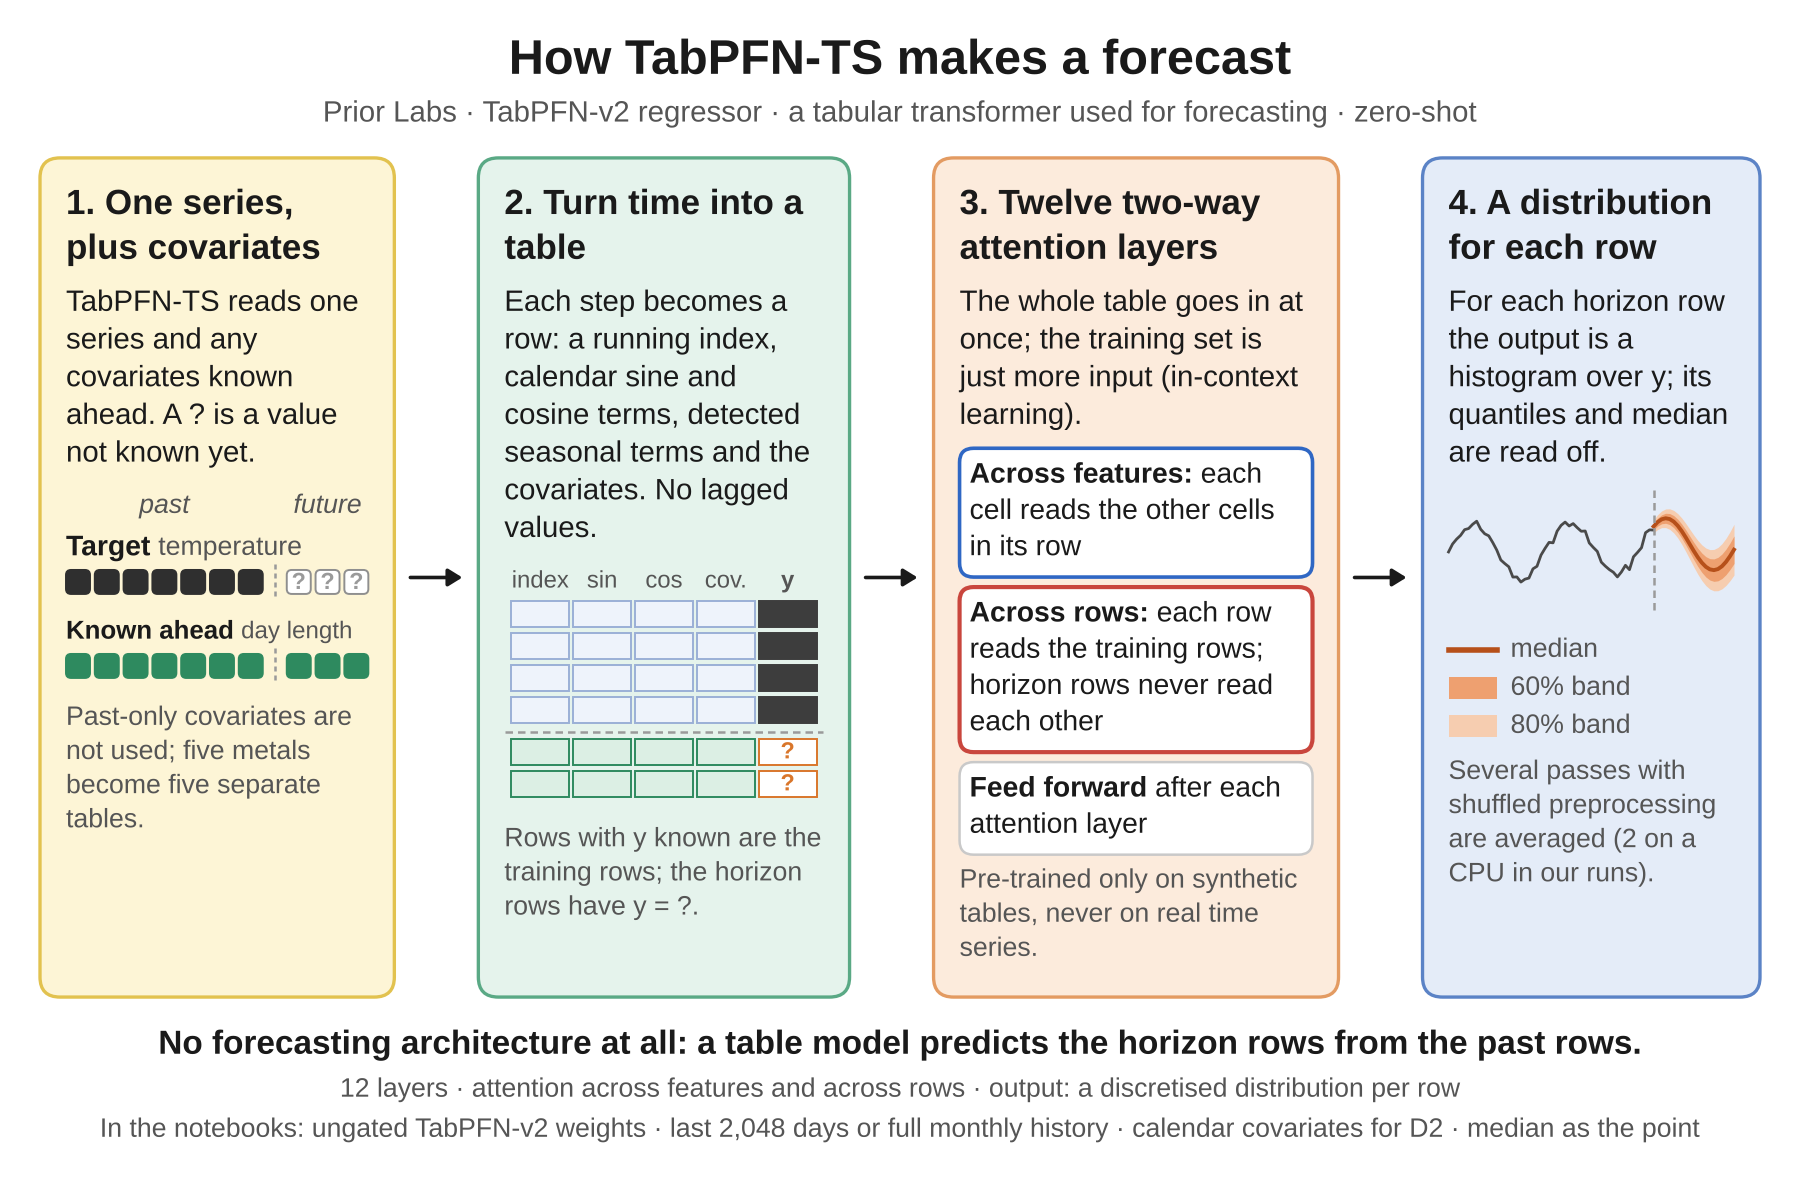

In [17]:
fig = figure("tabpfn-ts", path=FIG / "tabpfn-ts.png")

#### The maths behind the figure

The figure names the model's main components. Their equations follow, in the order in which the data passes through them.

**Scaled dot-product attention** compares each token's query $Q$ with the keys $K$ of the tokens it may read, and a softmax turns the scores into weights that mix their values $V$:

$$\mathrm{softmax}\left(\frac{QK^{\top}}{\sqrt{d_k}}\right)V$$

Every token is thus rebuilt from the tokens that matter for it.

#### What it costs to run

Attention over the rows costs O(R² · d) for R = T + H rows, multiplied by the number of features for the attention across features. That makes it the slowest model on a CPU here, so its context is capped.

#### Covariates

Without fine-tuning, TabPFN-TS (v2 weights) can read known-future covariates, but not past-only ones. It forecasts each target series on its own. The known-future covariates become extra feature columns of the regression table.

#### Where the figure comes from

The figure was checked against the model's paper, its released code and configuration, and the code this chapter
runs. The main sources for its components:

| Component in the figure | Source |
|---|---|
| features: running index, calendar, auto seasonal; no lag features | Hoo et al. 2025, Sec. 3 |
| TabPFN-v2 two-way attention (features, samples), outputs a discretised distribution | Hollmann et al. 2025 (Nature), Methods |
| ungated v2 regressor weights used | tabpfn-time-series 1.3.0; adapter note |
| 12 layers in TabPFN-v2 regressor | Hollmann et al. 2025, Methods |

#### The code

This chapter's adapter for TabPFN-TS (v2 weights) is the class `TabPFNTS` in [`src/ch03_zeroshot/models/others.py`](src/ch03_zeroshot/models/others.py) (line 102): it loads the checkpoint [`Prior-Labs/TabPFN-v2-reg`](https://huggingface.co/Prior-Labs/TabPFN-v2-reg), hands the model our context (and the covariates it can read) and turns its output into quantiles. All adapters share the interface `ZeroShotForecaster` in [`models/base.py`](src/ch03_zeroshot/models/base.py), and `run_model` in [`runner.py`](src/ch03_zeroshot/runner.py) runs it over every dataset, horizon and window. The network itself, layer by layer, is implemented in the `tabpfn-time-series` 1.3.0 library, which calls the TabPFN network from the `tabpfn` library ([PyPI page](https://pypi.org/project/tabpfn-time-series/1.3.0/)). The figure above is drawn by [`architectures.py`](src/ch03_zeroshot/architectures.py).

In [18]:
forecast("tabpfn-ts")

Predicting time series:   0%|          | 0/1 [00:00<?, ?it/s]

Predicting time series: 100%|██████████| 1/1 [00:12<00:00, 12.11s/it]

Predicting time series: 100%|██████████| 1/1 [00:12<00:00, 12.11s/it]

Predicting time series:   0%|          | 0/1 [00:00<?, ?it/s]

Predicting time series: 100%|██████████| 1/1 [00:11<00:00, 11.77s/it]

Predicting time series: 100%|██████████| 1/1 [00:11<00:00, 11.77s/it]

... (8 outputs left out)

Predicting time series:   0%|          | 0/5 [00:00<?, ?it/s]

Predicting time series: 100%|██████████| 5/5 [00:00<00:00, 848.74it/s]

TabPFN-TS (Prior-Labs/TabPFN-v2-reg): 0.0M parameters, loaded in 2.3 s


,status,seconds,covariates read,notes
dataset,,,,
D1,ran,24.0,none,
D2,ran,27.6,"fourier_sin_1, fourier_cos_1, fourier_sin_2, fourier_cos_2, daylength_h",
D3,ran,25.0,none,
D4,D3 forecasts reused,0.0,none,"reads none of these covariates, so its input is exactly D3's"


## 3 · Results of the full runs

The tables below read the stored forecasts of every horizon and rolling window (or your own, after
`FULL_RUN = True`). The helper functions behind them (scores, tables, plots and gain tables) are in
[`src/ch03_zeroshot/report.py`](src/ch03_zeroshot/report.py), and the metrics in
[`metrics.py`](src/ch03_zeroshot/metrics.py).

Each model's point forecast is its median, or its mean for the models that output one. Two errors score it. The
**MASE** (mean absolute scaled error) divides the mean absolute error of the forecast by the mean absolute error
that a naive rule makes on the history up to the forecast origin $T$:

$$\mathrm{MASE} = \frac{\frac{1}{H}\sum_{h=1}^{H}\left|y_{T+h}-\hat y_{T+h}\right|}{\frac{1}{T-\ell}\sum_{t=\ell+1}^{T}\left|y_t-y_{t-\ell}\right|}.$$

The naive rule repeats the value from $\ell$ steps earlier: the same day last year for temperature ($\ell = 365$), and the last value for metal prices ($\ell = 1$).
A MASE below 1 means that the model's errors were smaller than the errors the naive rule made on the history. The
**RMSE**, the root mean squared error, squares the errors before averaging, so it punishes large misses more.

Notebook 11 adds more metrics and compares every model of the chapter. This section looks
only at the models of this notebook, next to the naive and seasonal naive forecasts.

#### MASE by dataset and horizon

The best value in each row is in bold.

On D2 and D4 a model that cannot read the covariates gets exactly its D1 or D3 input, so its rows there repeat its D1 or D3 rows (the naive and seasonal naive rules read no covariates at all).

In [19]:
fc = load_forecasts(ROOT, MODELS + ["naive", "snaive"], DATASETS)
agg = aggregate(scores_cached(ROOT, MODELS + ["naive", "snaive"], DATASETS))
show_horizon_table(agg, "MASE", MODELS + ["naive", "snaive"], NAMES)

#### RMSE by dataset and horizon

The same table for the root mean squared error. Squaring the errors before averaging makes the RMSE weigh large
misses more than the MASE does, so a model that is usually close but sometimes far off looks worse here. To average over the five metals, whose prices differ by a factor of about ten,
the mean squared error (MSE) of the forecast is divided by the mean squared error of the naive rule on the history,
and the square root of the ratio is taken. The result is the root mean squared scaled error (RMSSE), whose weighted
form was the accuracy metric of the M5 forecasting competition:

$$\mathrm{MSE} = \frac{1}{H}\sum_{h=1}^{H}\left(y_{T+h}-\hat y_{T+h}\right)^2, \qquad \mathrm{MSE}_ {\text{naive}} = \frac{1}{T-\ell}\sum_{t=\ell+1}^{T}\left(y_t-y_{t-\ell}\right)^2,$$

$$\mathrm{RMSSE} = \sqrt{\mathrm{MSE} / \mathrm{MSE}_ {\text{naive}}}.$$

Below 1 again means smaller errors than the naive rule made on the history. Notebook 11 shows
the RMSE in the units of the data for every series.

In [20]:
show_horizon_table(agg, "RMSSE", MODELS + ["naive", "snaive"], NAMES)

#### Actual values against the forecasts

There is one figure per dataset, with one row of panels per series (all five metals on D3 and D4) and one panel per horizon. Each
panel shows the recent history (grey), what actually happened (black) and the point forecast of each model, all from
the same test window. Window 1 is the most recent one and ends at the last observation, so the longer horizons
start further back in time. To show fewer series, change `SERIES` (for example to `"copper"` for one metal); to look at an older
window, change `WINDOW` (daily data has 5 rolling windows, monthly data 3, and 1 at 24 months). On D2 and D4 only the models that read the covariates are drawn: the others'
forecasts are identical to their D1 or D3 forecasts.

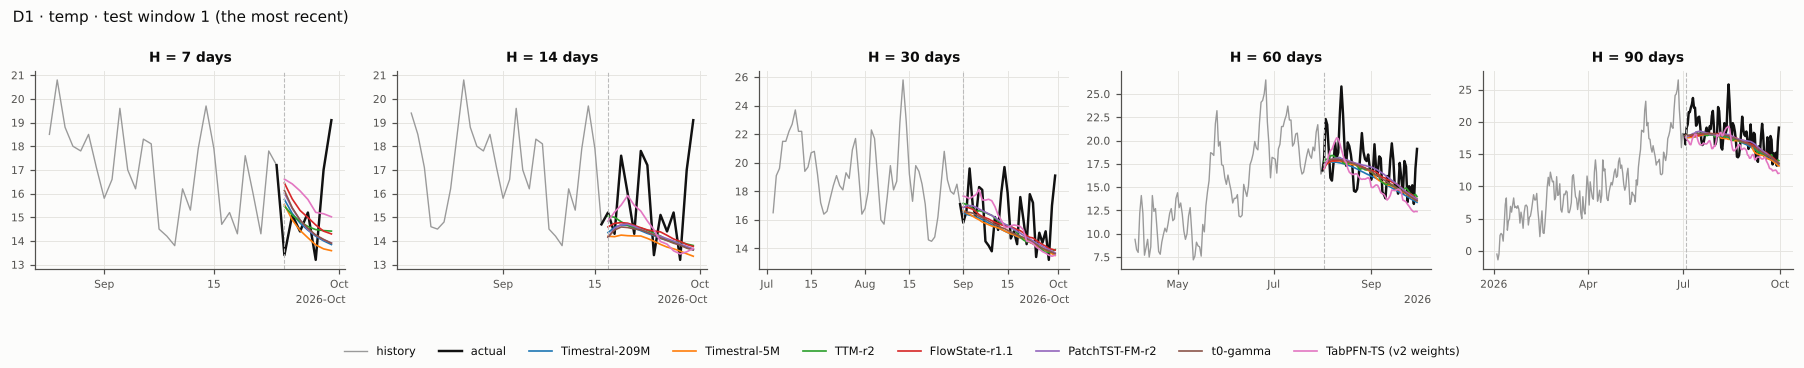

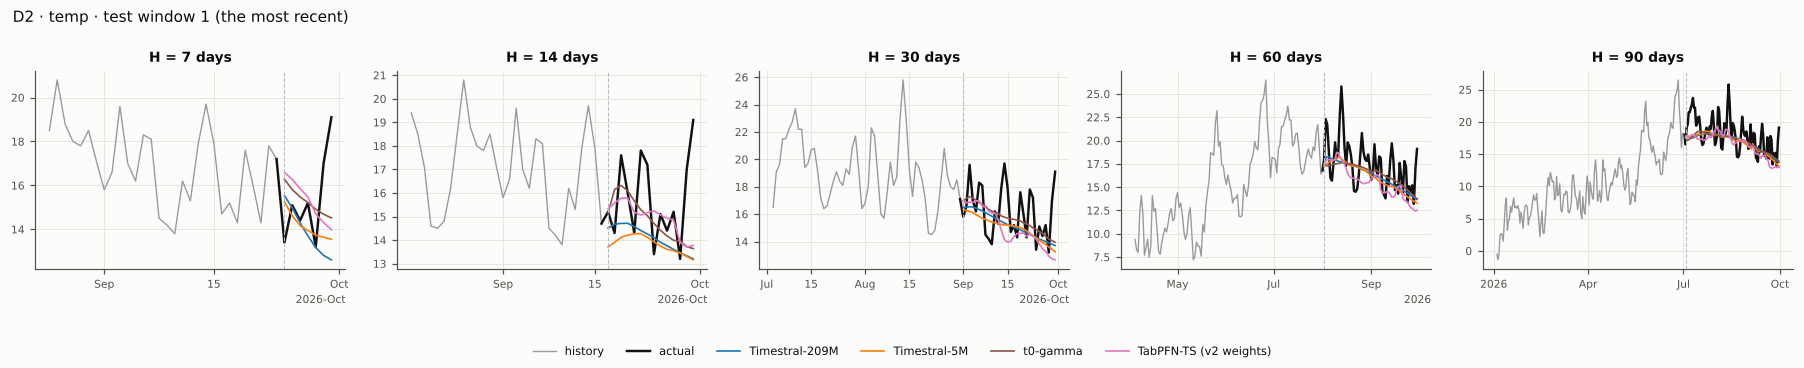

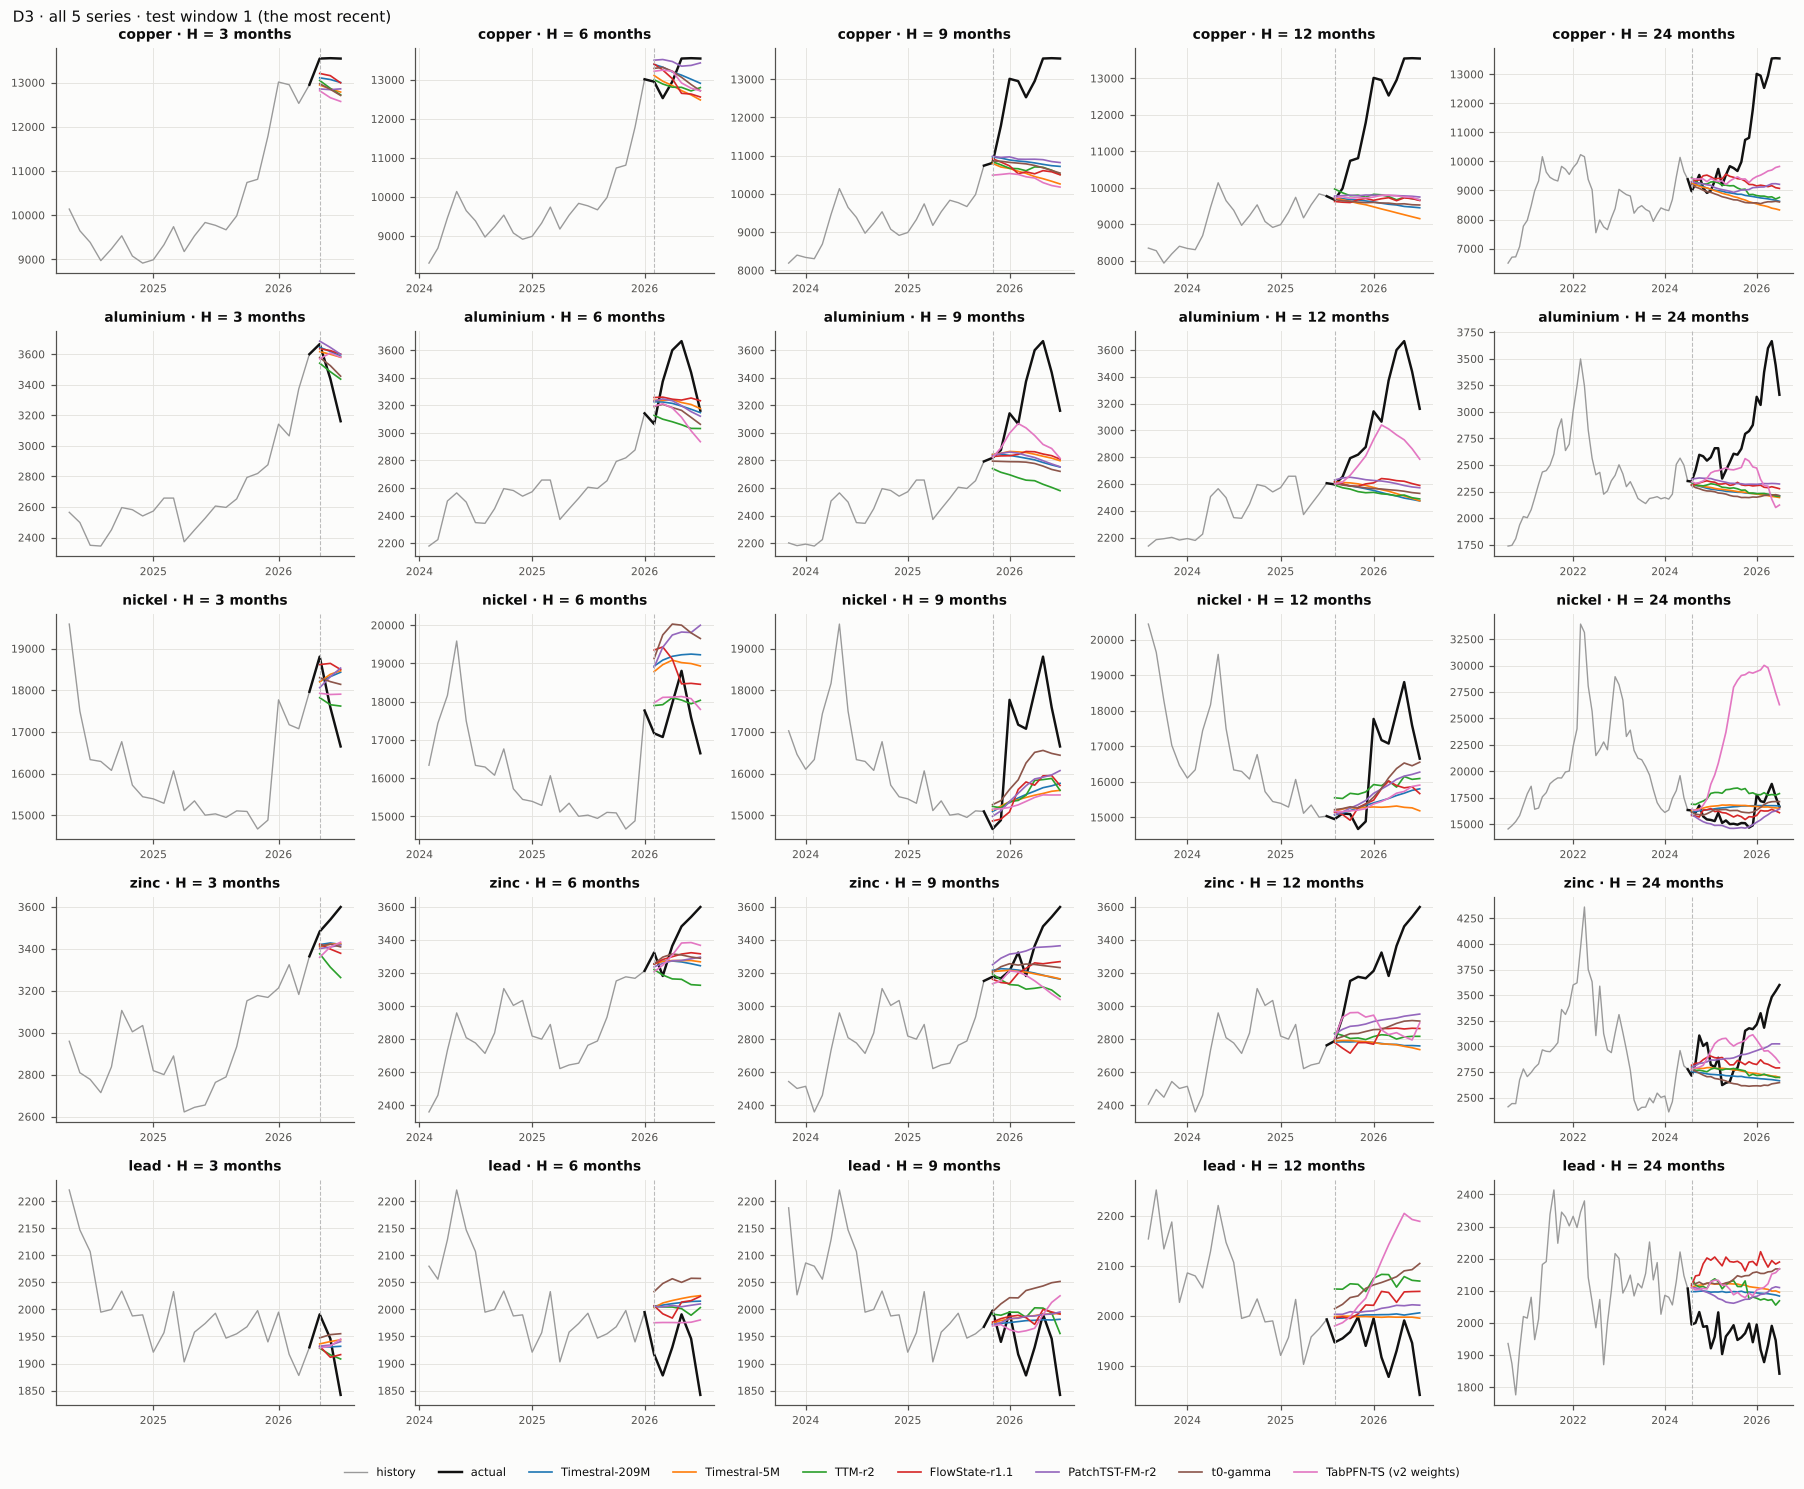

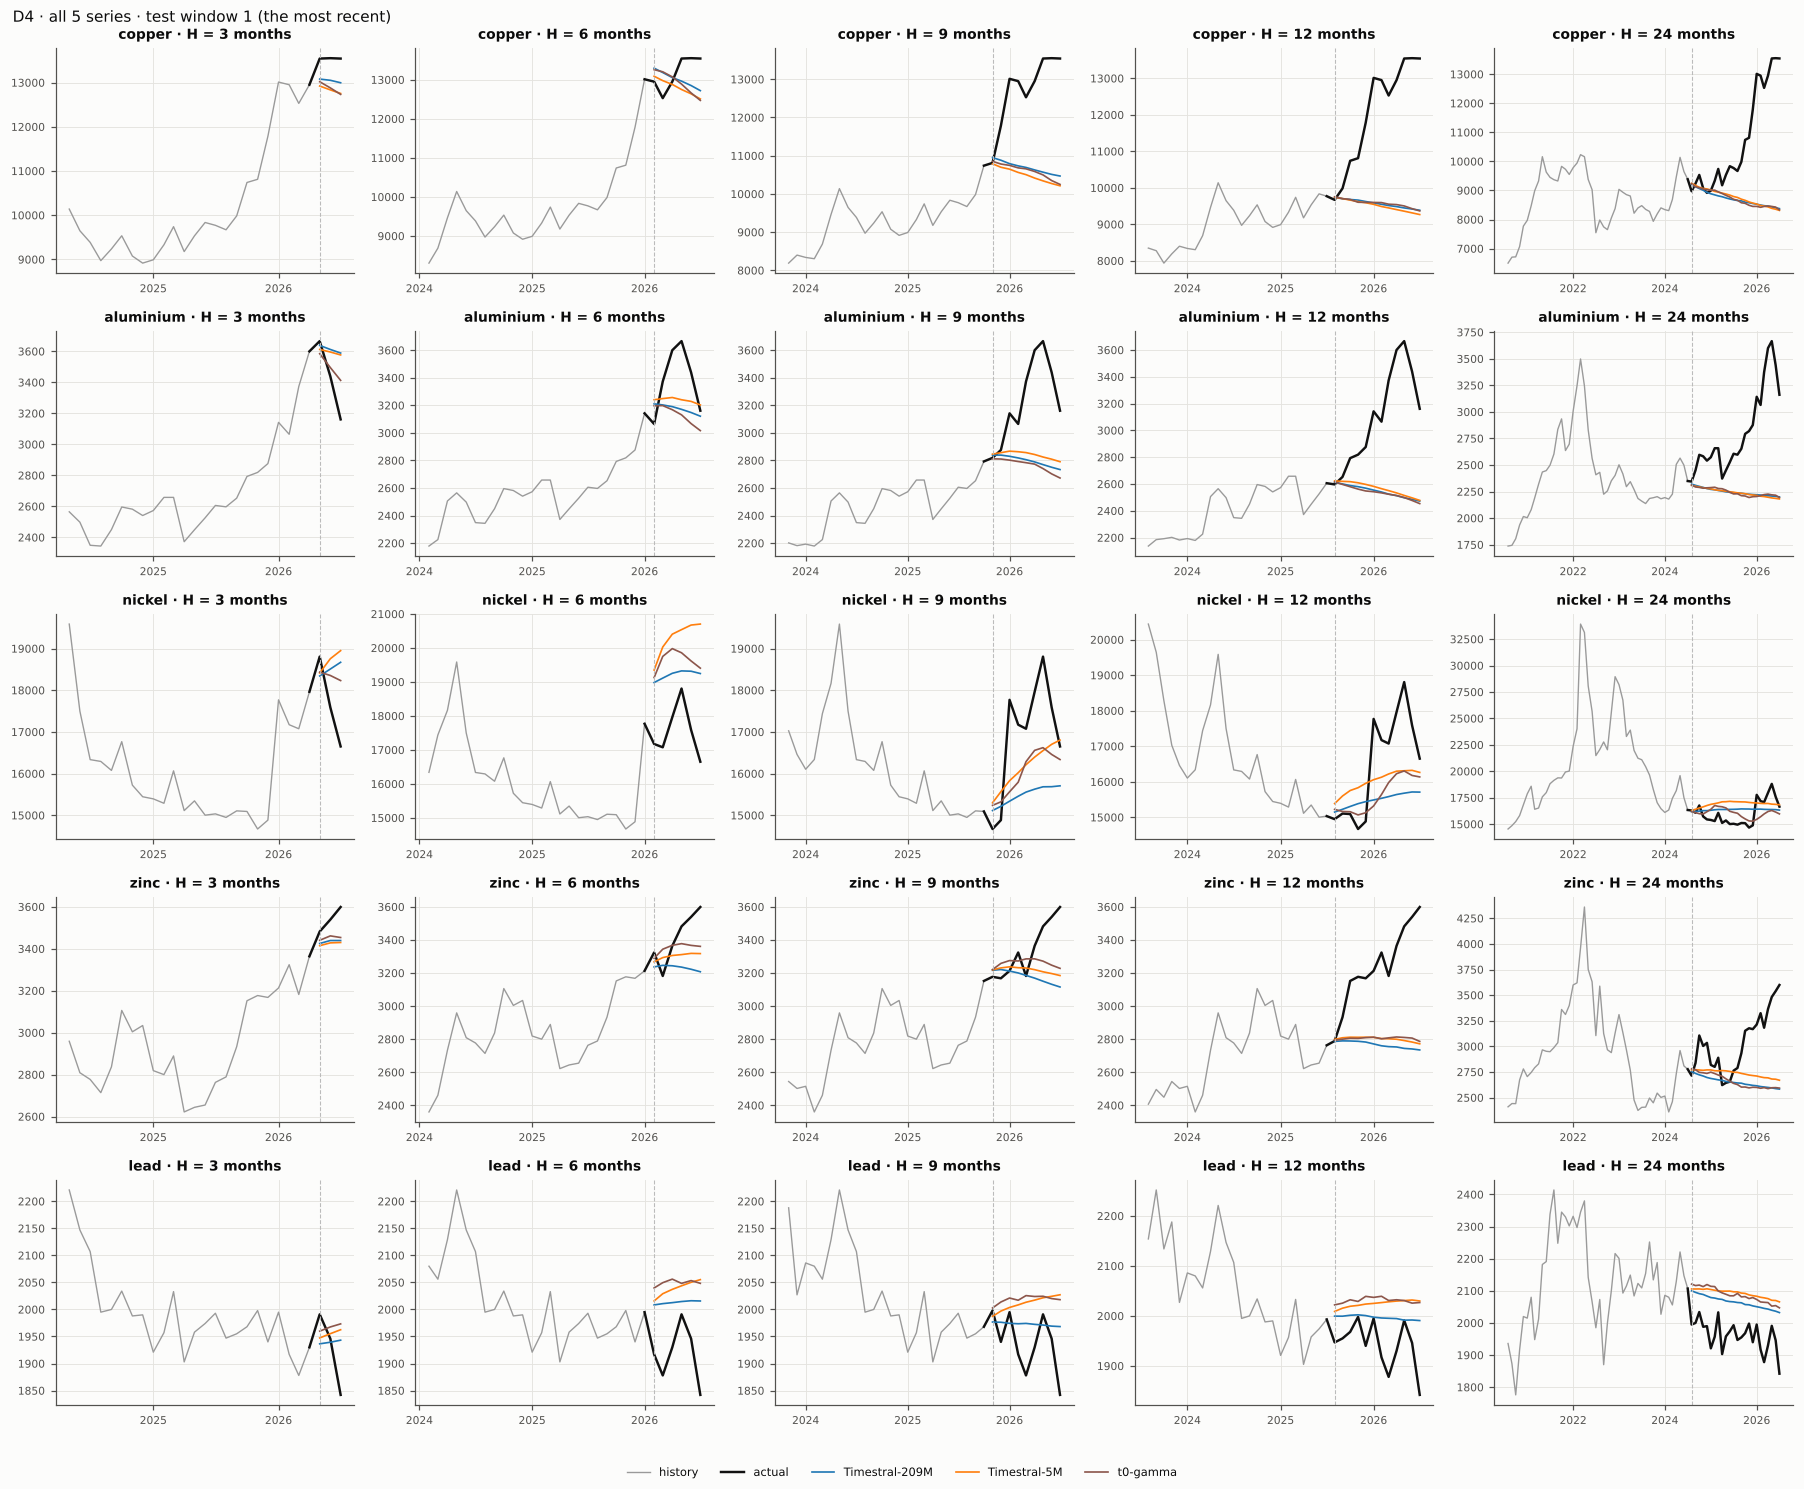

In [21]:
# the series to show: "all", one name or a list of names;
# D3 and D4 hold copper, aluminium, nickel, zinc and lead
SERIES = {"D1": "temp", "D2": "temp", "D3": "all", "D4": "all"}
WINDOW = 1  # 1 = the most recent test window
frames = {d: load_frame(ROOT, d) for d in DATASETS}
figs = forecast_gallery(fc, frames, SERIES, MODELS, NAMES, window=WINDOW)

#### The forecasts in numbers

For each dataset, the table shows the actual values and every model's point forecast at one horizon of the same test window, with the naive and seasonal naive rules as baselines.
`SERIES` and `WINDOW` work as in the plots above, so there is one table per series; change `HORIZON` to see another
horizon. In each row the forecast closest to the actual value is in bold. The grey rows underneath summarise the
window: the MAE, the RMSE and the mean error ME = mean(actual − forecast), which is positive when the forecasts were
too low. The best value of each is in bold. One window is a small sample, so these numbers can rank the models
differently from the averages over all windows in the tables above. Every horizon of the window is saved as a CSV
file in `results/tables/forecast_vs_actual/`.

In [22]:
HORIZON = {"D1": 14, "D2": 14, "D3": 6, "D4": 6}   # D1, D2: 7, 14, 30, 60 or 90 days; D3, D4: 3, 6, 9, 12 or 24 months
show_forecast_tables(fc, SERIES, HORIZON, MODELS + ["naive", "snaive"], NAMES, window=WINDOW, datasets=list(frames),
                     save=RESULTS / "tables" / "forecast_vs_actual" / "05b.csv")

**D1 · temp · H = 14 days · test window 1** (2026-09-17 to 2026-09-30)

,actual,Timestral-209M,Timestral-5M,TTM-r2,FlowState-r1.1,PatchTST-FM-r2,t0-gamma,TabPFN-TS (v2 weights),Naive (RW),Seasonal naive
2026-09-17,15.20,14.35,14.20,15.05,14.59,14.16,14.16,14.83,14.70,15.10
2026-09-18,14.30,14.57,14.18,15.00,14.74,14.53,14.46,15.22,14.70,17.70
2026-09-19,17.60,14.67,14.25,14.81,14.77,14.69,14.59,15.51,14.70,18.80
2026-09-20,16.00,14.66,14.22,14.66,14.75,14.70,14.57,15.92,14.70,15.90
2026-09-21,14.30,14.54,14.21,14.56,14.66,14.62,14.51,15.50,14.70,10.80
2026-09-22,17.80,14.43,14.21,14.55,14.56,14.49,14.47,15.26,14.70,9.30
2026-09-23,17.20,14.32,14.11,14.44,14.47,14.36,14.37,14.84,14.70,9.80
2026-09-24,13.40,14.22,13.99,14.32,14.42,14.27,14.25,14.47,14.70,12.10
2026-09-25,15.10,14.11,13.85,14.21,14.38,14.20,14.12,13.97,14.70,11.60
2026-09-26,14.40,14.03,13.74,14.04,14.24,14.09,14.01,13.86,14.70,10.80


**D2 · temp · H = 14 days · test window 1** (2026-09-17 to 2026-09-30)

,actual,Timestral-209M,Timestral-5M,t0-gamma,TabPFN-TS (v2 weights),Naive (RW),Seasonal naive
2026-09-17,15.20,14.51,13.71,15.14,15.32,14.70,15.10
2026-09-18,14.30,14.68,13.91,16.15,15.58,14.70,17.70
2026-09-19,17.60,14.71,14.11,16.32,15.78,14.70,18.80
2026-09-20,16.00,14.71,14.21,16.10,15.78,14.70,15.90
2026-09-21,14.30,14.57,14.27,15.67,15.18,14.70,10.80
2026-09-22,17.80,14.41,14.27,15.29,15.06,14.70,9.30
2026-09-23,17.20,14.26,14.12,15.04,15.16,14.70,9.80
2026-09-24,13.40,14.10,13.93,14.70,15.24,14.70,12.10
2026-09-25,15.10,13.91,13.75,14.41,15.07,14.70,11.60
2026-09-26,14.40,13.76,13.61,14.18,14.93,14.70,10.80


**D3 · copper · H = 6 months · test window 1** (2026-02-01 to 2026-07-01)

,actual,Timestral-209M,Timestral-5M,TTM-r2,FlowState-r1.1,PatchTST-FM-r2,t0-gamma,TabPFN-TS (v2 weights),Naive (RW),Seasonal naive
2026-02-01,"12,951","13,392","13,108","13,000","13,403","13,500","13,290","13,217","13,012","9,331"
2026-03-01,"12,529","13,323","12,962","12,891","13,249","13,518","13,318","13,246","13,012","9,740"
2026-04-01,"12,951","13,200","12,852","12,809","13,028","13,467","13,218","13,219","13,012","9,177"
2026-05-01,"13,543","13,118","12,721","12,805","12,652","13,347","13,062","12,918","13,012","9,533"
2026-06-01,"13,552","13,014","12,611","12,713","12,634","13,367","12,878","12,784","13,012","9,835"
2026-07-01,"13,543","12,910","12,482","12,799","12,559","13,430","12,718","12,716","13,012","9,771"
MAE,,513,586,479,674,425,563,578,368,"3,614"
RMSE,,541,696,571,746,521,602,622,427,"3,634"
ME (actual - forecast),,19,389,342,257,-260,97,162,166,"3,614"


... (15 outputs left out)

,actual,Timestral-209M,Timestral-5M,t0-gamma,Naive (RW),Seasonal naive
2026-02-01,"3,324","3,237","3,268","3,289","3,213","2,800"
2026-03-01,"3,182","3,246","3,293","3,344","3,213","2,889"
2026-04-01,"3,364","3,244","3,306","3,367","3,213","2,622"
2026-05-01,"3,482","3,236","3,311","3,377","3,213","2,644"
2026-06-01,"3,539","3,223","3,319","3,367","3,213","2,655"
2026-07-01,"3,599","3,208","3,317","3,361","3,213","2,763"
MAE,,204,150,119,212,686
RMSE,,238,171,144,246,718
ME (actual - forecast),,183,113,64,202,686


**D4 · lead · H = 6 months · test window 1** (2026-02-01 to 2026-07-01)

,actual,Timestral-209M,Timestral-5M,t0-gamma,Naive (RW),Seasonal naive
2026-02-01,"1,917","2,008","2,016","2,040","1,995","1,957"
2026-03-01,"1,878","2,011","2,029","2,050","1,995","2,033"
2026-04-01,"1,930","2,013","2,037","2,056","1,995","1,903"
2026-05-01,"1,991","2,015","2,044","2,048","1,995","1,958"
2026-06-01,"1,946","2,016","2,050","2,053","1,995","1,974"
2026-07-01,"1,842","2,016","2,055","2,048","1,995","1,993"
MAE,,96,121,132,78,72
RMSE,,107,131,140,91,92
ME (actual - forecast),,-96,-121,-132,-78,-52


Every horizon of window 1 saved to /home/user/fresh/repo/Chapter03_Zero_Shot_Forecasting/results/tables/forecast_vs_actual/05b.csv


#### Do the covariates help, by MASE and by RMSE?

For every model in this notebook that reads covariates, the tables give the % change in the error when the model gets the covariates:
D2 (the twelve temperature covariates) against D1, and D4 (three drivers, past values only) against D3. Negative
(green) means the covariates helped, positive (red) that they hurt. The MASE change says whether the typical error
shrank; the RMSE change, because it squares the errors, says whether the large misses shrank. When the two
disagree, the covariates helped with one kind of error only.

Three points help in reading the tables:

- **Daily and monthly results are in separate tables.** D2 against D1 is scored at 7 to 90 days and the metals at
  3 to 24 months. In one shared table every daily row would have empty cells (NaN, "not a number") under the monthly
  horizons and every monthly row under the daily ones: there was nothing to compute there, not a failed run.
- **A model is listed only where it read covariates.** A model that cannot read a kind of covariate ignores it, so
  its D2 or D4 forecasts are identical to its D1 or D3 forecasts and there is no gain to report. For example
  TimesFM-2.5 (Notebook 05a) reads only known-future covariates: it appears on D2, whose annual harmonics and day
  length are known in advance, but not on D4, whose drivers are past-only.
- **The RMSE change is measured series by series.** For temperature it is exactly the change in RMSE; for the
  metals it is the change in the scaled RMSE (RMSSE), so that nickel, at about 16,000 dollars a tonne, does not
  outweigh lead at about 2,000. An "n/a" would mark a horizon a model did not run.

In [23]:
gains = gain_tables(agg, MODELS, NAMES)
show_gains(gains)

**Daily temperature, D2 against D1 (horizons in days)**: % change in MASE and in RMSE when the model reads the covariates

**Monthly metals, D4 against D3 (horizons in months)**: % change in MASE and in RMSE when the model reads the covariates

**MASE against RMSE**: mean change over the horizons, and at how many horizons each metric improves

#### What the runs cost

The time spent forecasting, in seconds, over all horizons and rolling windows on 4 CPU cores. A value of 0.0 means that the model reads none of that dataset's covariates, so its D1 or D3 forecasts were reused.

In [24]:
runs = run_summary(ROOT, MODELS)
cost_table(runs, DATASETS)

dataset,D1,D2,D3,D4
model,,,,
FlowState-r1.1,48.7,0.0,30.5,0.0
PatchTST-FM-r2,49.7,0.0,41.2,0.0
TTM-r2,5.3,0.0,1.3,0.0
TabPFN-TS,1534.7,1542.9,503.8,0.0
Timestral-209M,13.2,372.0,11.2,28.3
Timestral-5M,0.8,16.9,0.6,1.2
t0-gamma,12.2,103.0,7.9,10.6


## 4 · Key insights


- **Tiny models hold their own on temperature.** TTM-r2, with 0.8M weights, reaches a mean MASE of 0.676 on D1, level
  with the best model of Notebook 05a (Chronos-Bolt, 0.672) at less than 2% of its size. Timestral-5M (0.695) is only 1%
  behind Timestral-209M (0.689) with 40 times fewer weights. Six of the seven models of this notebook lie between
  0.676 and 0.695 (TabPFN-TS, last bullet, scores 0.729), against 0.858 for the seasonal naive forecast.
- **FlowState needs its time scale.** The runs use the model card's setting (one year per cycle), and the check in
  section 2.4, on five validation windows that end before the first test window, shows why: with the hourly default
  the MAE at 30 days is 38% higher on D1, and 17% higher on the metals at 12 months. A zero-shot model still has to
  be told what its inputs are.
- **On metals only PatchTST-FM beats the random walk on average** (2.69 against 2.76); the others score 2.88 to 3.14.
  At 3 months Timestral-5M, FlowState and Timestral-209M (1.84 to 1.86) are level with the random walk (1.83); the gap
  opens at longer horizons, where only PatchTST-FM (4.14 at 24 months) stays below the random walk (4.23).
- **Covariates help these models little, and at different horizons than in Notebook 05a.** With D2's twelve
  covariates Timestral-209M and t0-gamma get worse at 7 days (by 8% and 7%) and slightly better at 30 to 90 days
  (by 0.5% to 1.8%); Timestral-5M improves by about 2% at every horizon. D4's three past-only drivers mostly hurt
  (Timestral-209M 3% to 6% worse from 6 to 24 months, Timestral-5M 6% worse at 3 and 6 months).
- **RMSE mostly agrees with MASE, except for t0-gamma at 7 days.** The two metrics move in the same direction in 29
  of the 35 cells of the gain tables, and all but one of the six exceptions are changes below 1.5%. The clear one is
  t0-gamma on D2 at 7 days: its MASE rises by 7% while its RMSE falls by 1%, so the covariates add many small errors
  but no large misses. Timestral-209M at 7 days is the reverse case: its RMSE rises more (11%) than its MASE (8%),
  so its extra error comes from a few large misses.
- **Cost differs by orders of magnitude, and covariates multiply it.** Timestral-5M forecasts every window of D1 in
  0.8 s and TTM in 5 s; Timestral-209M needs 13 s for D1 but 372 s for D2, where it also reads the twelve
  covariates.
- **TabPFN-TS is the slowest model here, and not the most accurate.** It turns every time step into a table row
  (running index, calendar and seasonal terms) and lets a tabular foundation model (TabPFN-v2 weights, which need no
  licence token) predict the horizon rows. With two ensemble passes on a CPU it needs 1,535 s for D1, for a mean MASE
  of 0.729 (8% behind TTM-r2). D2's calendar covariates help it at 30 and 90 days (by about 6%) but not at 7 and 14
  days (3% worse): its own calendar features already carry the season. On metals it is level with the random walk up
  to 6 months (1.92 and 2.05 against 1.83 and 2.06) and behind it after that.

## References

- Timestral-209M: Mistral AI (2026), [arXiv:2610.37585](https://arxiv.org/abs/2610.37585); [model card](https://huggingface.co/mistralai/Timestral-209M)
- Timestral-5M: Mistral AI (2026), [arXiv:2610.37585](https://arxiv.org/abs/2610.37585); [model card](https://huggingface.co/mistralai/Timestral-5M)
- TTM-r2: Ekambaram et al. (2024), [arXiv:2401.03955](https://arxiv.org/abs/2401.03955); [model card](https://huggingface.co/ibm-granite/granite-timeseries-ttm-r2)
- FlowState-r1.1: Graf et al. (2025), [arXiv:2508.05287](https://arxiv.org/abs/2508.05287); [model card](https://huggingface.co/ibm-granite/granite-timeseries-flowstate-r1)
- PatchTST-FM-r2: [model card](https://huggingface.co/ibm-granite/granite-timeseries-patchtst-fm-r2)
- t0-gamma: Meyer et al. (2026), [arXiv:2609.24559](https://arxiv.org/abs/2609.24559); [model card](https://huggingface.co/theforecastingcompany/t0-gamma)
- TabPFN-TS (v2 weights): Hoo et al. (2025), [arXiv:2501.02945](https://arxiv.org/abs/2501.02945); [model card](https://huggingface.co/Prior-Labs/TabPFN-v2-reg)
- Raschka, S. (2024). *Build a Large Language Model (From Scratch)*. Manning, ISBN 978-1-63343-716-6. Code: [github.com/rasbt/LLMs-from-scratch](https://github.com/rasbt/LLMs-from-scratch)
- Hyndman, R. J., & Koehler, A. B. (2006). Another look at measures of forecast accuracy. *International Journal of Forecasting*, 22(4), 679-688 (MASE). [doi:10.1016/j.ijforecast.2006.03.001](https://doi.org/10.1016/j.ijforecast.2006.03.001)